<a href="https://colab.research.google.com/github/MaryemBourourou/arabica-coffee-quality-eda/blob/main/eda_arabica_coffee.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ☕ Qu'est-ce qui fait un grand café arabica ?
## Exploration de données et valeur ajoutée de la visualisation

**Matière :** Initiation à la data science — ISSAT Sousse — ING-A3
**Fichier de données :** `arabica_data_cleaned.csv` (dossier `Datasets`)

> ℹ️ Ce notebook a été exécuté sur les données réelles : tous les chiffres cités dans les commentaires sont lus dans les résultats affichés juste au-dessus. Il fonctionne avec pandas ≥ 2 et seaborn ≥ 0.13.

---

### Problématique

> **Qu'est-ce qui distingue un lot de café arabica de haute qualité : son pays d'origine, son altitude, sa méthode de traitement, ses défauts ? Et dans quelle mesure un bon nettoyage et un bon choix de graphiques changent-ils nos conclusions par rapport à une lecture « brute » des données ?**

### Questions de recherche

| N° | Question | Variables utilisées | Section |
|----|----------|--------------------|---------|
| Q1 | Comment le score total est-il distribué ? Quelle part des lots atteint la classe « spécialité » (≥ 80) ? | `score_total` | D |
| Q2 | Quels critères de dégustation pèsent le plus dans le score ? Sont-ils redondants ? | 10 notes + total | D, E.1-E.2 |
| Q3 | Les pays se distinguent-ils vraiment, et au-delà de la moyenne ? | `pays`, `score_total` | E.3 |
| Q4 | L'altitude est-elle liée au score ? Cette relation tient-elle **à l'intérieur** de chaque pays ? | `altitude_m`, `pays` | E.4 |
| Q5 | La méthode de traitement (lavé / naturel) donne-t-elle de meilleurs scores ? | `traitement`, `pays` | E.5 |
| Q6 | Le score évolue-t-il dans le temps ? Les défauts font-ils baisser le score ? | `annee`, `defauts_cat2` | E.6-E.7 |
| Q7 | Les lots atypiques sont-ils des erreurs ou des cas réels ? | `score_total` | E.8 |

### Plan
**A.** Présentation → **B.** Exploration initiale (diagnostic) → **C.** Nettoyage → **D.** Analyse univariée → **E.** Analyse bivariée / multivariée → **F.** Bilan et conclusion.

### Fil rouge : « bon graphique vs mauvais graphique »
Dans ce projet, plusieurs questions sont traitées **deux fois** avec des graphiques différents, pour montrer qu'un même jeu de données peut paraître sans intérêt ou riche d'informations selon la représentation choisie.

---
# A. Présentation du dataset

### Sujet et source
Le fichier décrit des **lots de café arabica** évalués par des dégustateurs professionnels (« cuppers »). Chaque ligne = un lot, avec son pays d'origine, sa variété, sa méthode de traitement, son altitude, ses défauts physiques et **10 notes de dégustation** dont la somme donne le **score total** (`Total.Cup.Points`).

*Source : Coffee Quality Database (données du Coffee Quality Institute), disponible sur GitHub (jldbc/coffee-quality-database) et sur Kaggle.*

### Objectif de l'étude
Comprendre ce qui est associé à un score élevé, **sans prétendre démontrer de causalité** (nous ne faisons que de l'exploration, pas de l'expérimentation).

### Chargement

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)   # pour voir toutes les colonnes

In [ ]:

raw = pd.read_csv("arabica_data_cleaned.csv")

print("Dimensions (lignes, colonnes) :", raw.shape)
raw.head()

Dimensions (lignes, colonnes) : (1311, 44)


,Unnamed: 0,Species,Owner,Country.of.Origin,Farm.Name,Lot.Number,Mill,ICO.Number,Company,Altitude,Region,Producer,Number.of.Bags,Bag.Weight,In.Country.Partner,Harvest.Year,Grading.Date,Owner.1,Variety,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points,Moisture,Category.One.Defects,Quakers,Color,Category.Two.Defects,Expiration,Certification.Body,Certification.Address,Certification.Contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
0,1,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,NaN,Washed / Wet,8.67,8.83,8.67,8.75,8.50,8.42,10.0,10.0,10.0,8.75,90.58,0.12,0,0.0,Green,0,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
1,2,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.75,8.67,8.50,8.58,8.42,8.42,10.0,10.0,10.0,8.58,89.92,0.12,0,0.0,Green,1,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0
2,3,Arabica,grounds for health admin,Guatemala,"san marcos barrancas ""san cristobal cuch",NaN,NaN,NaN,NaN,1600 - 1800 m,NaN,NaN,5,1,Specialty Coffee Association,NaN,"May 31st, 2010",Grounds for Health Admin,Bourbon,NaN,8.42,8.50,8.42,8.42,8.33,8.42,10.0,10.0,10.0,9.25,89.75,0.00,0,0.0,NaN,0,"May 31st, 2011",Specialty Coffee Association,36d0d00a3724338ba7937c52a378d085f2172daa,0878a7d4b9d35ddbf0fe2ce69a2062cceb45a660,m,1600.0,1800.0,1700.0
3,4,Arabica,yidnekachew dabessa,Ethiopia,yidnekachew dabessa coffee plantation,NaN,wolensu,NaN,yidnekachew debessa coffee plantation,1800-2200,oromia,Yidnekachew Dabessa Coffee Plantation,320,60 kg,METAD Agricultural Development plc,2014,"March 26th, 2015",Yidnekachew Dabessa,NaN,Natural / Dry,8.17,8.58,8.42,8.42,8.50,8.25,10.0,10.0,10.0,8.67,89.00,0.11,0,0.0,Green,2,"March 25th, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1800.0,2200.0,2000.0
4,5,Arabica,metad plc,Ethiopia,metad plc,NaN,metad plc,2014/2015,metad agricultural developmet plc,1950-2200,guji-hambela,METAD PLC,300,60 kg,METAD Agricultural Development plc,2014,"April 4th, 2015",metad plc,Other,Washed / Wet,8.25,8.50,8.25,8.50,8.42,8.33,10.0,10.0,10.0,8.58,88.83,0.12,0,0.0,Green,2,"April 3rd, 2016",METAD Agricultural Development plc,309fcf77415a3661ae83e027f7e5f05dad786e44,19fef5a731de2db57d16da10287413f5f99bc2dd,m,1950.0,2200.0,2075.0


On voit **44 colonnes** (beaucoup d'informations administratives : propriétaire, certificateur, adresse hachée…). La première étape intellectuelle consiste à décider **quelles colonnes servent notre problématique**. Voici les colonnes retenues :

| Colonne (nom d'origine) | Signification | Type |
|---|---|---|
| `Country.of.Origin` | Pays d'origine du lot | catégorielle |
| `Variety` | Variété de caféier (Caturra, Bourbon…) | catégorielle |
| `Processing.Method` | Méthode de traitement après récolte (Washed/Wet, Natural/Dry…) | catégorielle |
| `Color` | Couleur du grain vert | catégorielle |
| `Harvest.Year` | Année de récolte (texte libre, voir B) | texte |
| `Grading.Date` | Date du classement (ex. « April 4th, 2015 ») | date (à convertir) |
| `Number.of.Bags` | Nombre de sacs du lot | numérique |
| `Aroma`, `Flavor`, `Aftertaste`, `Acidity`, `Body`, `Balance`, `Cupper.Points` | 7 notes de dégustation (≈ 5 à 9 sur 10) | numériques |
| `Uniformity`, `Clean.Cup`, `Sweetness` | 3 notes de régularité (≈ 10 sur 10) | numériques |
| `Total.Cup.Points` | **Score total = somme des 10 notes** (variable cible de l'étude) | numérique |
| `Moisture` | Taux d'humidité du grain | numérique |
| `Category.One.Defects`, `Category.Two.Defects`, `Quakers` | Défauts physiques (cat. 1 = graves, cat. 2 = moins graves), grains immatures | numériques (entiers) |
| `Altitude`, `unit_of_measurement`, `altitude_mean_meters` | Altitude en texte libre, unité, et valeur moyenne en mètres calculée dans le fichier | texte / numérique |

**Colonnes écartées** : `Species` (toujours « Arabica »), `Unnamed: 0` (simple numéro), `Owner`, `Farm.Name`, `Mill`, `Company`, `Producer`, `Certification.*`… (identifiants administratifs sans lien avec nos questions).

In [ ]:
raw.tail(3)

,Unnamed: 0,Species,Owner,Country.of.Origin,Farm.Name,Lot.Number,Mill,ICO.Number,Company,Altitude,Region,Producer,Number.of.Bags,Bag.Weight,In.Country.Partner,Harvest.Year,Grading.Date,Owner.1,Variety,Processing.Method,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points,Moisture,Category.One.Defects,Quakers,Color,Category.Two.Defects,Expiration,Certification.Body,Certification.Address,Certification.Contact,unit_of_measurement,altitude_low_meters,altitude_high_meters,altitude_mean_meters
1308,1309,Arabica,"exportadora atlantic, s.a.",Nicaragua,finca las marías,017-053-0211/ 017-053-0212,beneficio atlantic condega,017-053-0211/ 017-053-0212,exportadora atlantic s.a,1100,jalapa,Teófilo Narváez,550,69 kg,Instituto Hondureño del Café,2016,"June 6th, 2017","Exportadora Atlantic, S.A.",Caturra,Other,7.25,6.58,6.33,6.25,6.42,6.08,6.0,6.00,6.00,6.17,63.08,0.13,1,0.0,Green,5,"June 6th, 2018",Instituto Hondureño del Café,b4660a57e9f8cc613ae5b8f02bfce8634c763ab4,7f521ca403540f81ec99daec7da19c2788393880,m,1100.00,1100.00,1100.00
1309,1310,Arabica,juan luis alvarado romero,Guatemala,finca el limon,NaN,beneficio serben,11/853/165,unicafe,4650,nuevo oriente,WILLIAM ESTUARDO MARTINEZ PACHECO,275,1 kg,Asociacion Nacional Del Café,2012,"May 24th, 2012",Juan Luis Alvarado Romero,Catuai,Washed / Wet,7.50,6.67,6.67,7.67,7.33,6.67,8.0,1.33,1.33,6.67,59.83,0.10,0,0.0,Green,4,"May 24th, 2013",Asociacion Nacional Del Café,b1f20fe3a819fd6b2ee0eb8fdc3da256604f1e53,724f04ad10ed31dbb9d260f0dfd221ba48be8a95,ft,1417.32,1417.32,1417.32
1310,1312,Arabica,bismarck castro,Honduras,los hicaques,103,cigrah s.a de c.v.,13-111-053,cigrah s.a de c.v,1400,comayagua,Reinerio Zepeda,275,69 kg,Instituto Hondureño del Café,2017,"April 28th, 2017",Bismarck Castro,Caturra,NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00,0.00,0.12,0,0.0,Green,2,"April 28th, 2018",Instituto Hondureño del Café,b4660a57e9f8cc613ae5b8f02bfce8634c763ab4,7f521ca403540f81ec99daec7da19c2788393880,m,1400.00,1400.00,1400.00


In [ ]:
# On ne garde que les colonnes utiles à notre problématique (voir tableau ci-dessus)
colonnes_utiles = [
    "Country.of.Origin", "Variety", "Processing.Method", "Color",
    "Harvest.Year", "Grading.Date", "Number.of.Bags",
    # les 10 critères de dégustation (notes) + le total
    "Aroma", "Flavor", "Aftertaste", "Acidity", "Body", "Balance",
    "Uniformity", "Clean.Cup", "Sweetness", "Cupper.Points", "Total.Cup.Points",
    # mesures physiques / défauts
    "Moisture", "Category.One.Defects", "Category.Two.Defects", "Quakers",
    # altitude : texte d'origine + valeur numérique en mètres déjà calculée dans le fichier
    "Altitude", "unit_of_measurement", "altitude_mean_meters",
]
brut = raw[colonnes_utiles].copy()   # .copy() : on ne modifie jamais raw
print(brut.shape)

(1311, 25)


---
# B. Exploration initiale : le diagnostic

> **Règle :** on **découvre et on mesure** les problèmes *avant* de les corriger. Pour chaque vérification, on explique ce qu'on cherche.

## B.1 Structure et types — `info()`
*Pourquoi ?* Vérifier que chaque colonne a le bon type (une date lue comme du texte, un nombre lu comme du texte…) et repérer les colonnes incomplètes.

In [ ]:
brut.info()

<class 'pandas.DataFrame'>
RangeIndex: 1311 entries, 0 to 1310
Data columns (total 25 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Country.of.Origin     1310 non-null   str    
 1   Variety               1110 non-null   str    
 2   Processing.Method     1159 non-null   str    
 3   Color                 1044 non-null   str    
 4   Harvest.Year          1264 non-null   str    
 5   Grading.Date          1311 non-null   str    
 6   Number.of.Bags        1311 non-null   int64  
 7   Aroma                 1311 non-null   float64
 8   Flavor                1311 non-null   float64
 9   Aftertaste            1311 non-null   float64
 10  Acidity               1311 non-null   float64
 11  Body                  1311 non-null   float64
 12  Balance               1311 non-null   float64
 13  Uniformity            1311 non-null   float64
 14  Clean.Cup             1311 non-null   float64
 15  Sweetness             1311 non-n

**Constats.** 1311 lignes, 25 colonnes retenues. Les notes sont bien numériques. En revanche `Grading.Date` et `Harvest.Year` sont du **texte** : il faudra convertir la date. Plusieurs colonnes ont moins de 1311 valeurs non nulles : `Color`, `Variety`, `Processing.Method`, `Altitude`, `altitude_mean_meters`.

## B.2 Statistiques descriptives — `describe()`
*Pourquoi ?* Les minimums/maximums trahissent les valeurs impossibles ; moyenne vs médiane renseigne sur l'asymétrie.

In [ ]:
notes = ["Aroma", "Flavor", "Aftertaste", "Acidity", "Body", "Balance",
         "Uniformity", "Clean.Cup", "Sweetness", "Cupper.Points"]

brut[notes + ["Total.Cup.Points"]].describe().round(2)

,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points
count,1311.00,1311.00,1311.00,1311.00,1311.00,1311.00,1311.00,1311.00,1311.00,1311.00,1311.00
mean,7.56,7.52,7.40,7.53,7.52,7.52,9.83,9.83,9.90,7.50,82.12
std,0.38,0.40,0.41,0.38,0.36,0.41,0.56,0.77,0.53,0.47,3.52
min,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,7.42,7.33,7.25,7.33,7.33,7.33,10.00,10.00,10.00,7.25,81.17
50%,7.58,7.58,7.42,7.50,7.50,7.50,10.00,10.00,10.00,7.50,82.50
75%,7.75,7.75,7.58,7.75,7.67,7.75,10.00,10.00,10.00,7.75,83.67
max,8.75,8.83,8.67,8.75,8.58,8.75,10.00,10.00,10.00,10.00,90.58


In [ ]:
brut[["Number.of.Bags", "Moisture", "Category.One.Defects", "Category.Two.Defects", "Quakers", "altitude_mean_meters"]].describe().round(2)

,Number.of.Bags,Moisture,Category.One.Defects,Category.Two.Defects,Quakers,altitude_mean_meters
count,1311.00,1311.00,1311.00,1311.00,1310.00,1084.00
mean,153.89,0.09,0.43,3.59,0.18,1784.20
std,129.73,0.05,1.83,5.35,0.84,8767.02
min,0.00,0.00,0.00,0.00,0.00,1.00
25%,14.50,0.09,0.00,0.00,0.00,1100.00
50%,175.00,0.11,0.00,2.00,0.00,1310.64
75%,275.00,0.12,0.00,4.00,0.00,1600.00
max,1062.00,0.28,31.00,55.00,11.00,190164.00


**Constats importants (à repérer dans les tableaux ci-dessus) :**
- Le **minimum de toutes les notes est 0**, alors que les quartiles sont autour de 7,3 à 7,8 (ou 10 pour les trois dernières notes). Un score total de **0** est suspect.
- L'**altitude moyenne** (1784 m) est très éloignée de la **médiane** (1311 m), et l'écart-type vaut **8767 m**, avec un **maximum de 190 164 m** : l'Everest fait 8849 m. Il s'agit forcément d'une erreur de saisie.
- Les notes `Uniformity`, `Clean.Cup`, `Sweetness` ont une médiane de **10** et un 25ᵉ percentile de **10** : la plupart des lots ont déjà la note maximale.
- L'**humidité** a un minimum de 0,00 ; nous y reviendrons.

## B.3 Valeurs manquantes
*Pourquoi ?* Une valeur manquante peut fausser une moyenne, empêcher un calcul ou révéler un biais de collecte.

                      nb_manquants  pourcentage
Color                          267         20.4
altitude_mean_meters           227         17.3
Altitude                       223         17.0
Variety                        201         15.3
Processing.Method              152         11.6
Harvest.Year                    47          3.6
Country.of.Origin                1          0.1
Quakers                          1          0.1


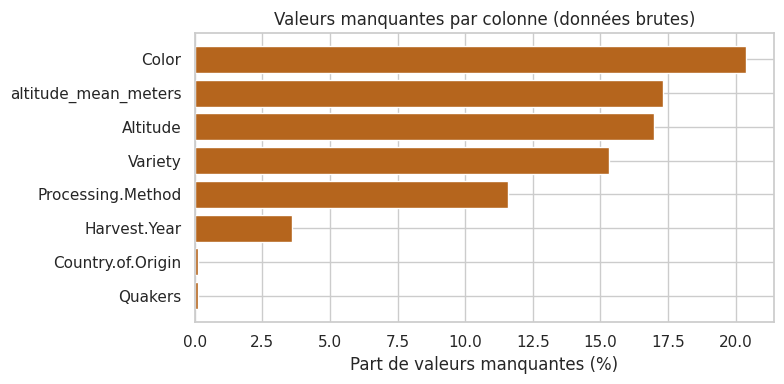

In [ ]:
# Valeurs manquantes : nombre et pourcentage par colonne
nb_nan = brut.isna().sum()
pct_nan = (nb_nan / len(brut) * 100).round(1)
manquants = pd.DataFrame({"nb_manquants": nb_nan, "pourcentage": pct_nan})
manquants = manquants[manquants["nb_manquants"] > 0].sort_values("pourcentage", ascending=False)
print(manquants)

# Visualisation : diagramme en barres horizontales (noms longs -> barres horizontales)
plt.figure(figsize=(8, 4))
plt.barh(manquants.index[::-1], manquants["pourcentage"][::-1], color="#b5651d")
plt.xlabel("Part de valeurs manquantes (%)")
plt.title("Valeurs manquantes par colonne (données brutes)")
plt.tight_layout()
plt.show()

**Interprétation.** Quatre colonnes manquent de façon importante : `Color` (20,4 %), `altitude_mean_meters` (17,3 %), `Variety` (15,3 %) et `Processing.Method` (11,6 %). Les notes de dégustation, elles, sont **complètes** (aucune valeur manquante) : l'essentiel de l'analyse sur le score est donc possible.
**Choix de graphique :** barres horizontales car les noms de colonnes sont longs et on compare des pourcentages. **Limite :** ce graphique dit *combien* il manque, pas *pourquoi* ; nous testerons plus loin si l'absence d'altitude est liée au score.

## B.4 Doublons
*Pourquoi ?* Un lot compté deux fois fausse les effectifs et les moyennes. On cherche d'abord les doublons **exacts**, puis les **quasi-doublons** (même producteur, même pays, même score, même récolte).

In [ ]:
# 1) Doublons exacts (toutes les colonnes identiques)
print("Doublons exacts :", brut.duplicated().sum())

# 2) Quasi-doublons : même propriétaire / ferme / pays / score / année de récolte
raw_cles = ["Owner", "Farm.Name", "Country.of.Origin", "Total.Cup.Points", "Harvest.Year"]
quasi = raw[raw.duplicated(subset=raw_cles, keep=False)].sort_values(raw_cles)
print("Lignes concernées par un quasi-doublon :", len(quasi))
quasi[["Owner", "Country.of.Origin", "Total.Cup.Points", "Aroma", "Flavor", "Aftertaste", "Grading.Date"]].head(8)

Doublons exacts : 0
Lignes concernées par un quasi-doublon : 50


,Owner,Country.of.Origin,Total.Cup.Points,Aroma,Flavor,Aftertaste,Grading.Date
1304,cadexsa,Honduras,69.17,7.00,6.17,6.17,"May 15th, 2014"
1305,cadexsa,Honduras,69.17,7.00,6.33,6.17,"May 15th, 2014"
515,carcafe ltda ci,Colombia,83.00,7.33,7.67,7.75,"March 15th, 2013"
516,carcafe ltda ci,Colombia,83.00,7.58,7.75,7.42,"April 26th, 2013"
351,carcafe ltda ci,Colombia,83.50,7.75,7.58,7.58,"February 20th, 2017"
354,carcafe ltda ci,Colombia,83.50,7.75,7.58,7.58,"April 7th, 2016"
343,compañia colombiana agroindustrial s.a,Colombia,83.58,7.67,7.58,7.67,"June 24th, 2014"
344,compañia colombiana agroindustrial s.a,Colombia,83.58,7.67,7.58,7.67,"March 13th, 2014"


In [ ]:
# Ces lignes sont-elles identiques sur l'ensemble des colonnes de notes ?
colonnes_sans_id = [c for c in raw.columns if c != "Unnamed: 0"]
print("Doublons sur TOUTES les colonnes (hors identifiant) :", raw.duplicated(subset=colonnes_sans_id).sum())

Doublons sur TOUTES les colonnes (hors identifiant) : 0


**Interprétation.** Il n'y a **aucun doublon exact**. Il y a pourtant 50 lignes qui partagent producteur, pays, score total et année de récolte. En les regardant de près, **leurs notes diffèrent** (ex. `Flavor` 6,17 vs 6,33) et leurs dates de classement aussi : ce sont des **lots différents** du même producteur, pas des copies. Les supprimer aurait retiré des données réelles.
👉 **Décision : on ne supprime rien.** C'est un bon exemple de l'esprit critique : *une ressemblance n'est pas un doublon*.

## B.5 Incohérences (règles métier, formats)
*Pourquoi ?* Une donnée peut être « présente » mais fausse. On vérifie des règles que les données doivent respecter.

In [ ]:
# --- Règle métier 1 : un lot ne peut pas avoir un score total de 0
print("Lots avec score total = 0 :", (brut["Total.Cup.Points"] == 0).sum())
print("Lots avec au moins une note = 0 :", (brut[notes] == 0).any(axis=1).sum())
brut[(brut[notes] == 0).any(axis=1)][["Country.of.Origin"] + notes + ["Total.Cup.Points"]]

Lots avec score total = 0 : 1
Lots avec au moins une note = 0 : 2


,Country.of.Origin,Aroma,Flavor,Aftertaste,Acidity,Body,Balance,Uniformity,Clean.Cup,Sweetness,Cupper.Points,Total.Cup.Points
1306,Mexico,7.08,6.83,6.25,7.42,7.25,6.75,10.0,0.0,10.0,6.75,68.33
1310,Honduras,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.0,0.0,0.00,0.00


**Constat.** Deux lots ont au moins une note à 0 :
- Le lot **Honduras** (275 sacs) a **toutes** ses notes à 0 et un score total de 0 : il n'a manifestement **pas été évalué** (impossible pour un café réellement dégusté).
- Le lot **Mexique** n'a qu'une note à 0 (`Clean.Cup`) mais un score total cohérent (68,33) : cela peut correspondre à une vraie dégustation sévère. On le **garde**.

In [ ]:
# --- Règle métier 2 : chaque note doit être comprise entre 0 et 10 (méthode between, cf. TP3)
hors_echelle = brut[notes].apply(lambda col: (~col.between(0, 10)).sum())
print("Notes hors de [0, 10] par colonne :\n", hors_echelle.to_string())

# --- Règle métier 3 : le score total doit être la somme des 10 notes (tolérance d'arrondi 0.05)
ecart = (brut[notes].sum(axis=1) - brut["Total.Cup.Points"]).abs()
print("\nLots où total != somme des 10 notes :", (ecart > 0.05).sum(), "sur", len(brut))

Notes hors de [0, 10] par colonne :
 Aroma            0
Flavor           0
Aftertaste       0
Acidity          0
Body             0
Balance          0
Uniformity       0
Clean.Cup        0
Sweetness        0
Cupper.Points    0

Lots où total != somme des 10 notes : 2 sur 1311


**Constat.** Toutes les notes sont bien dans l'intervalle [0 ; 10]. Le total est égal à la somme des 10 notes pour 1309 lots sur 1311 (les 2 écarts sont de petits arrondis) : **le fichier est cohérent sur ce point**, et on pourra utiliser le total sans crainte.

In [ ]:
# --- Altitude : valeur numérique calculée par le fichier (en mètres)
print(brut["altitude_mean_meters"].describe().round(1))

print("\nAltitudes < 100 m  :", (brut["altitude_mean_meters"] < 100).sum())
print("Altitudes > 3000 m :", (brut["altitude_mean_meters"] > 3000).sum())

# Les valeurs les plus extrêmes : texte d'origine vs valeur numérique
brut.sort_values("altitude_mean_meters", ascending=False)[
    ["Country.of.Origin", "Altitude", "altitude_mean_meters"]].head(6)

count      1084.0
mean       1784.2
std        8767.0
min           1.0
25%        1100.0
50%        1310.6
75%        1600.0
max      190164.0
Name: altitude_mean_meters, dtype: float64

Altitudes < 100 m  : 18
Altitudes > 3000 m : 14


,Country.of.Origin,Altitude,altitude_mean_meters
1144,Guatemala,1901.64,190164.0
896,Guatemala,190164,190164.0
1040,Nicaragua,1100.00 mosl,110000.0
543,Brazil,11000 metros,11000.0
1098,Myanmar,4287,4287.0
840,Myanmar,4001,4001.0


**Constat.** Le tableau montre que les altitudes extrêmes viennent de **fautes de saisie** : `1901.64` est lu comme `190164`, `1100.00 mosl` comme `110000`, `11000 metros` comme `11000`. À l'inverse, 18 lots ont une altitude **inférieure à 100 m** (souvent `1` ou `1.2`), vraisemblablement un mètre confondu avec un kilomètre ou une valeur par défaut. Au total, **32 altitudes** sont hors de la plage plausible (100–3000 m).

In [ ]:
# --- Autres incohérences de format
print("Humidité = 0 :", (brut["Moisture"] == 0).sum(), "lots sur", len(brut))
print("Humidité médiane des lots > 0 :", brut.loc[brut["Moisture"] > 0, "Moisture"].median())

annee = brut["Harvest.Year"].dropna()
non_standard = annee[~annee.str.fullmatch(r"\d{4}")]
print("\n'Harvest.Year' : valeurs qui ne sont pas une année à 4 chiffres :", len(non_standard), "sur", len(annee))
print(non_standard.unique()[:12].tolist())

print("\nExemple de 'Grading.Date' :", brut["Grading.Date"].iloc[0])
print("Pays avec caractère suspect :", [p for p in brut["Country.of.Origin"].dropna().unique() if "?" in p])

Humidité = 0 : 252 lots sur 1311
Humidité médiane des lots > 0 : 0.11

'Harvest.Year' : valeurs qui ne sont pas une année à 4 chiffres : 164 sur 1264
['March 2010', 'Sept 2009 - April 2010', 'May-August', '2009/2010', '2015/2016', 'Fall 2009', '2009 / 2010', '2010-2011', '2009-2010', '2009 - 2010', '2013/2014', '2017 / 2018']

Exemple de 'Grading.Date' : April 4th, 2015
Pays avec caractère suspect : ['Cote d?Ivoire']


**Constats.**
- **Humidité = 0** pour 252 lots, alors que la médiane des autres lots est 0,11 : un grain de café n'a pas 0 % d'humidité, c'est très probablement **« non mesuré »** codé par 0.
- **`Harvest.Year`** est du texte libre : 164 valeurs sur 1264 ne sont pas une année simple (« 2009/2010 », « May-August », « Fall 2009 »…). Cette colonne est trop désordonnée pour une analyse temporelle fiable.
- **`Grading.Date`** est exploitable après conversion : on l'utilisera comme repère temporel.
- Le pays **`Cote d?Ivoire`** contient un caractère abîmé (problème d'encodage).

## B.6 Valeurs aberrantes (IQR et z-score)
*Pourquoi ?* Repérer des valeurs extrêmes, puis **juger** si ce sont des erreurs (à corriger) ou des cas réels (à garder).

In [ ]:
# Méthode IQR
def bornes_iqr(serie):
    q1, q3 = serie.quantile(0.25), serie.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

for col in ["Total.Cup.Points", "altitude_mean_meters", "Category.Two.Defects"]:
    s = brut[col].dropna()
    bas, haut = bornes_iqr(s)
    n_hors = ((s < bas) | (s > haut)).sum()
    print(f"{col:22s} bornes IQR = [{bas:7.1f} ; {haut:8.1f}]  -> {n_hors} valeurs hors bornes")

# Méthode z-score sur l'altitude
alt = brut["altitude_mean_meters"].dropna()
z = (alt - alt.mean()) / alt.std()
print("\nAltitudes avec |z| > 3 :", (z.abs() > 3).sum(), "->", sorted(alt[z.abs() > 3].tolist()))

Total.Cup.Points       bornes IQR = [   77.4 ;     87.4]  -> 74 valeurs hors bornes
altitude_mean_meters   bornes IQR = [  350.0 ;   2350.0]  -> 61 valeurs hors bornes
Category.Two.Defects   bornes IQR = [   -6.0 ;     10.0]  -> 94 valeurs hors bornes

Altitudes avec |z| > 3 : 3 -> [110000.0, 190164.0, 190164.0]


**Interprétation.** Les deux méthodes ne disent pas la même chose :
- **Altitude** : le z-score isole précisément 3 valeurs absurdes (110 000 m et deux fois 190 164 m). L'IQR en signale 61 car il est plus sévère, mais la plupart sont simplement des altitudes basses ou hautes **réalistes**. Ici, on a besoin d'une **règle métier** (plage 100–3000 m) plus que d'une règle purement statistique.
- **Score total** : l'IQR signale 74 lots hors de [77,4 ; 87,4]. Ce sont surtout des lots de score bas ou très haut : nous verrons en E.8 que ce sont des **cas réels**, pas des erreurs (sauf le lot à 0).

## B.7 Tableau de diagnostic:

In [ ]:
# Tableau de diagnostic:
n_zero_total = int((brut["Total.Cup.Points"] == 0).sum())
n_alt_abs = int(((brut["altitude_mean_meters"] < 100) | (brut["altitude_mean_meters"] > 3000)).sum())
n_humid0 = int((brut["Moisture"] == 0).sum())
n_cellules_nan = int(brut.isna().sum().sum())
n_format = int((~brut["Harvest.Year"].dropna().str.fullmatch(r"\d{4}")).sum() + brut["Country.of.Origin"].str.contains(r"\?", na=False).sum())

diagnostic = pd.DataFrame({
    "Famille": ["Doublons", "Incohérences", "Incohérences", "Incohérences",
                "Valeurs manquantes", "Valeurs aberrantes"],
    "Colonne(s) concernée(s)": ["toutes", "Total.Cup.Points / notes", "Moisture",
                                "Harvest.Year, Grading.Date, pays",
                                "Color, altitude, Variety, Processing.Method...",
                                "altitude_mean_meters"],
    "Nombre de problèmes": [int(brut.duplicated().sum()), n_zero_total, n_humid0,
                            n_format,
                            n_cellules_nan, n_alt_abs],
})
diagnostic

,Famille,Colonne(s) concernée(s),Nombre de problèmes
0,Doublons,toutes,0
1,Incohérences,Total.Cup.Points / notes,1
2,Incohérences,Moisture,252
3,Incohérences,"Harvest.Year, Grading.Date, pays",165
4,Valeurs manquantes,"Color, altitude, Variety, Processing.Method...",1119
5,Valeurs aberrantes,altitude_mean_meters,32


**Synthèse du diagnostic.**
| Famille | Verdict |
|---|---|
| Doublons | Aucun doublon exact ; quasi-doublons vérifiés = lots différents → **rien à supprimer** |
| Incohérences | 1 lot non évalué (score 0), 252 humidités à 0, formats d'année/date/pays hétérogènes |
| Valeurs manquantes | surtout `Color`, altitude, `Variety`, `Processing.Method` |
| Valeurs aberrantes | 32 altitudes impossibles |

*Remarque : ce tableau compte des **cellules** manquantes (1119) et non des lignes ; c'est pourquoi le chiffre est élevé.*

---
# C. Nettoyage et préparation

> **Principe :** ne corriger que ce qui a été réellement observé, dans un **ordre logique**  : doublons → incohérences → valeurs aberrantes → valeurs manquantes. Chaque décision est justifiée et on compare avant/après.

## C.1 Renommer les colonnes en français
On utilise des noms courts, sans point ni majuscule (plus faciles à taper).

In [ ]:
# Étape 1 : copie de travail + noms de colonnes en français (comme à l'étape 0 du TP2)
df = brut.copy()
df = df.rename(columns={
    "Country.of.Origin": "pays", "Variety": "variete", "Processing.Method": "traitement",
    "Color": "couleur", "Harvest.Year": "annee_recolte_txt", "Grading.Date": "date_classement",
    "Number.of.Bags": "nb_sacs",
    "Aroma": "arome", "Flavor": "saveur", "Aftertaste": "arriere_gout", "Acidity": "acidite",
    "Body": "corps", "Balance": "equilibre", "Uniformity": "uniformite",
    "Clean.Cup": "tasse_propre", "Sweetness": "douceur", "Cupper.Points": "impression",
    "Total.Cup.Points": "score_total", "Moisture": "humidite",
    "Category.One.Defects": "defauts_cat1", "Category.Two.Defects": "defauts_cat2",
    "Quakers": "quakers", "Altitude": "altitude_texte", "unit_of_measurement": "unite",
    "altitude_mean_meters": "altitude_m",
})
notes_fr = ["arome", "saveur", "arriere_gout", "acidite", "corps",
            "equilibre", "uniformite", "tasse_propre", "douceur", "impression"]
n_avant = len(df)
print("Lignes avant nettoyage :", n_avant)

Lignes avant nettoyage : 1311


## C.2 Lot impossible (score = 0)
**Décision : supprimer la ligne.** On ne peut ni la corriger ni l'imputer : toutes les notes sont à 0, le lot n'a jamais été évalué. Les imputer par une moyenne inventerait une dégustation qui n'a pas eu lieu.

In [ ]:
# Étape 2 : lot impossible (score total = 0) -> supprimé
df = df[df["score_total"] > 0].copy()
print("Lignes supprimées :", n_avant - len(df), "| lignes restantes :", len(df))

Lignes supprimées : 1 | lignes restantes : 1310


## C.3 Altitudes impossibles et humidité nulle
**Décision : remplacer par `NaN` (et non supprimer la ligne).** Le score de ces lots reste valide ; seule la colonne d'altitude est fausse. Supprimer la ligne ferait perdre de l'information utile. L'humidité à 0 est traitée de la même façon (hypothèse : « non mesuré »).

In [ ]:
# Étape 3 : altitudes impossibles -> NaN (jamais supprimer la ligne entière : le score reste valable)
avant = df["altitude_m"].isna().sum()
df["altitude_m"] = df["altitude_m"].where(df["altitude_m"].between(100, 3000))
# .where garde la valeur si la condition est vraie, sinon met NaN
print("Altitudes mises à NaN :", df["altitude_m"].isna().sum() - avant)

# Humidité = 0 : valeur physiquement impossible, interprétée comme "non mesurée" -> NaN
df["humidite"] = df["humidite"].replace(0, np.nan)
print("Humidité manquante après traitement :", df["humidite"].isna().sum())

Altitudes mises à NaN : 32
Humidité manquante après traitement : 252


## C.4 Harmonisation du pays et conversion des dates
`str.replace` pour le pays, `pd.to_datetime` pour la date (comme au TP3 II.5). On en déduit l'**année de classement**, plus fiable que `Harvest.Year`.

In [ ]:
# Étape 4 : harmonisation des textes
df["pays"] = df["pays"].str.replace("Cote d?Ivoire", "Côte d'Ivoire", regex=False)

# Dates : on retire "st/nd/rd/th" ("April 4th, 2015" -> "April 4, 2015") puis on convertit
texte_date = df["date_classement"].str.replace(r"(\d)(st|nd|rd|th)", r"\1", regex=True)
df["date_classement"] = pd.to_datetime(texte_date, format="%B %d, %Y", errors="coerce")
df["annee"] = df["date_classement"].dt.year
print("Dates non converties (NaT) :", df["date_classement"].isna().sum())
print("Période couverte :", df["date_classement"].min().date(), "->", df["date_classement"].max().date())

Dates non converties (NaT) : 2
Période couverte : 2010-04-09 -> 2018-01-19


## C.5 Valeurs manquantes
- **Catégories manquantes** (`pays`, `variete`, `traitement`, `couleur`) → « Inconnu » (technique du TP3 D.3) : on garde les lots sans les ranger dans une vraie catégorie. (`variete` et `couleur` ne sont pas exploitées plus loin ; elles sont conservées pour de futures analyses.)
- **Altitude manquante : pas d'imputation.** Imputer l'altitude par une médiane de pays créerait des valeurs artificielles et pourrait fabriquer une relation altitude/score. On vérifie d'abord que l'absence n'est pas liée au score :

In [ ]:
# Étape 5 : valeurs manquantes
# Catégories manquantes -> "Inconnu" (méthode du TP3, D.3)
for col in ["pays", "variete", "traitement", "couleur"]:
    df[col] = df[col].fillna("Inconnu")

# L'altitude manquante n'est PAS imputée. Vérifions d'abord que ce n'est pas "informatif" :
print(df.groupby(df["altitude_m"].isna())["score_total"].agg(["count", "mean", "median"]).round(2)
        .rename(index={False: "altitude connue", True: "altitude manquante"}))

                    count   mean  median
altitude_m                              
altitude connue      1051  82.21   82.58
altitude manquante    259  82.05   82.50


Les lots sans altitude ont un score moyen presque identique (82,05 contre 82,21) : **l'absence d'altitude ne semble pas biaiser le score**. On analysera donc l'altitude sur les lots où elle est connue (1051 lots), en le précisant à chaque fois.

## C.6 Création de nouvelles variables (discrétisation)
 on utilise `pd.cut` pour transformer des variables continues en classes **lisibles** :
- `classe_qualite` : **Standard** (< 80), **Spécialité** (80–85), **Excellent** (≥ 85). Le seuil de 80 points est une convention couramment utilisée dans le monde du café pour définir le café « de spécialité » ; nous l'adoptons comme repère, il ne vient pas de nos données.
- `classe_altitude` : quatre tranches.
- `classe_defauts` : 0, 1–5, 6 et plus défauts de catégorie 2.
- `defauts_total` : somme des défauts de catégories 1 et 2.

In [ ]:
# Étape 6 : nouvelles variables utiles à l'analyse
# (a) total des défauts
df["defauts_total"] = df["defauts_cat1"] + df["defauts_cat2"]

# (b) classe de qualité : pd.cut avec bornes (right=False : 80 appartient à "Spécialité")
df["classe_qualite"] = pd.cut(df["score_total"], bins=[0, 80, 85, 100], right=False,
                              labels=["Standard (<80)", "Spécialité (80-85)", "Excellent (>=85)"])

# (c) classe d'altitude
df["classe_altitude"] = pd.cut(df["altitude_m"], bins=[0, 1000, 1500, 2000, 3000],
                               labels=["<1000 m", "1000-1500 m", "1500-2000 m", ">2000 m"])

# (d) classe de défauts de catégorie 2
df["classe_defauts"] = pd.cut(df["defauts_cat2"], bins=[-1, 0, 5, 100],
                              labels=["0 défaut", "1-5 défauts", "6+ défauts"])

print(df["classe_qualite"].value_counts(dropna=False).sort_index())
print()
print(df["classe_altitude"].value_counts(dropna=False).sort_index())

classe_qualite
Standard (<80)         180
Spécialité (80-85)    1024
Excellent (>=85)       106
Name: count, dtype: int64

classe_altitude
<1000 m        196
1000-1500 m    517
1500-2000 m    324
>2000 m         14
NaN            259
Name: count, dtype: int64


**Lecture.** Sur 1310 lots : **180 Standard (13,7 %)**, **1024 Spécialité (78,2 %)** et **106 Excellent (8,1 %)**. La grande majorité des lots atteint donc déjà le seuil de 80 : le jeu de données contient peu de « mauvais » cafés. Seuls 14 lots dépassent 2000 m, ce qui limitera les conclusions sur cette tranche.

## C.7 Vérifications automatiques et comparaison avant / après

In [ ]:
# Vérifications automatiques (assert, comme au TP3 V.2) : si une règle est violée, une erreur s'affiche
assert (df["score_total"] > 0).all()
assert df[notes_fr].apply(lambda c: c.between(0, 10).all()).all()
assert df["altitude_m"].dropna().between(100, 3000).all()
assert df["date_classement"].dropna().dt.year.between(2009, 2018).all()
assert df["pays"].notna().all()
print("Toutes les vérifications sont passées.")

Toutes les vérifications sont passées.


In [ ]:
# Comparaison avant / après nettoyage
comparaison = pd.DataFrame({
    "avant": [len(brut), brut["Total.Cup.Points"].mean(), brut["Total.Cup.Points"].min(),
              brut["altitude_mean_meters"].mean(), brut["altitude_mean_meters"].max(),
              brut["altitude_mean_meters"].std()],
    "après": [len(df), df["score_total"].mean(), df["score_total"].min(),
              df["altitude_m"].mean(), df["altitude_m"].max(), df["altitude_m"].std()],
}, index=["nb de lots", "score total moyen", "score total minimum",
          "altitude moyenne (m)", "altitude maximale (m)", "écart-type altitude (m)"]).round(2)
comparaison

,avant,après
nb de lots,1311.00,1310.00
score total moyen,82.12,82.18
score total minimum,0.00,59.83
altitude moyenne (m),1784.20,1326.61
altitude maximale (m),190164.00,2560.00
écart-type altitude (m),8767.02,385.29


**Ce que le nettoyage a changé :**
- Le **score minimum** passe de 0 à 59,83 : le score moyen change peu (82,12 → 82,18) car un seul lot est retiré parmi 1311. **Le défaut le plus visible n'est donc pas celui qui change le plus la moyenne**, mais celui qui déforme les graphiques (voir D.1).
- L'**altitude** est celle qui change radicalement : moyenne 1784 m → 1327 m, **écart-type 8767 m → 385 m**, maximum 190 164 m → 2560 m. Sans nettoyage, toute statistique ou tout graphique sur l'altitude aurait été faux.

---
# D. Analyse univariée

> Chaque variable est d'abord étudiée **seule**. Pour chaque graphique : Question → Choix → Code → Interprétation → Conclusion → Limites.

## D.1 Pourquoi nettoyer avant de dessiner ? (Q1)
**Question.** Que voit-on dans la distribution du score total avant et après suppression du lot à 0 ?
**Choix du graphique.** Deux histogrammes côte à côte avec le **même axe vertical** pour comparer directement.

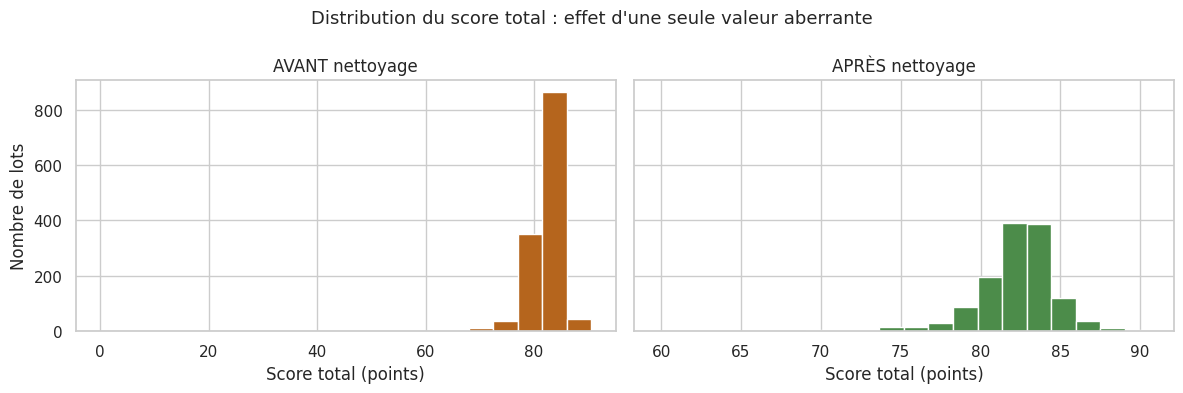

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

axes[0].hist(brut["Total.Cup.Points"], bins=20, color="#b5651d", edgecolor="white")
axes[0].set_title("AVANT nettoyage")
axes[0].set_xlabel("Score total (points)")
axes[0].set_ylabel("Nombre de lots")

axes[1].hist(df["score_total"], bins=20, color="#4c8c4a", edgecolor="white")
axes[1].set_title("APRÈS nettoyage")
axes[1].set_xlabel("Score total (points)")

fig.suptitle("Distribution du score total : effet d'une seule valeur aberrante", fontsize=13)
plt.tight_layout()
plt.show()

**Interprétation.** À gauche, l'axe horizontal va de 0 à 90 à cause **d'un seul lot** (sur 1311) : tous les autres sont écrasés entre 70 et 90 et la forme de la distribution est difficile à lire. À droite, l'axe se resserre sur 60–90 et on distingue une **distribution en cloche** centrée autour de 82–84, avec une queue vers les faibles scores.
**Conclusion.** Une seule valeur aberrante suffit à rendre un histogramme peu informatif : le nettoyage est un **préalable au graphique**, pas un détail.
**Limites.** L'histogramme ne dit pas *pourquoi* le lot vaut 0 ; c'est la vérification des données (B.5) qui l'explique.

## D.2 Combien de classes choisir pour un histogramme ?
**Question.** La forme de la distribution dépend-elle du nombre de classes ?
**Choix.** Trois histogrammes de la même variable avec 5, 20 et 60 classes.

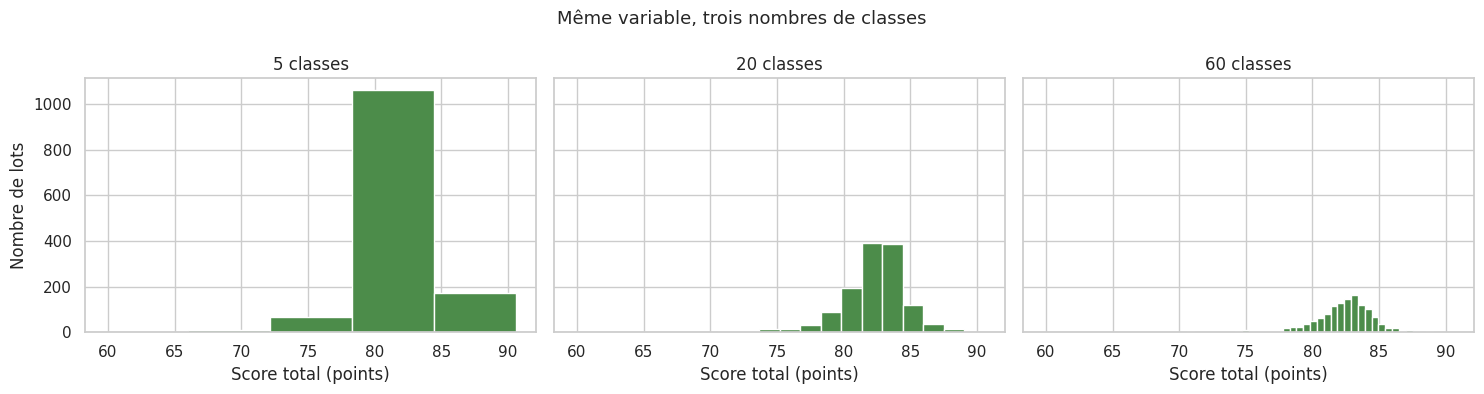

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, k in zip(axes, [5, 20, 60]):
    ax.hist(df["score_total"], bins=k, color="#4c8c4a", edgecolor="white")
    ax.set_title(f"{k} classes")
    ax.set_xlabel("Score total (points)")
axes[0].set_ylabel("Nombre de lots")
fig.suptitle("Même variable, trois nombres de classes", fontsize=13)
plt.tight_layout()
plt.show()

**Interprétation.** Avec **5 classes**, un seul bloc contient plus de 1000 lots : on ne voit plus la cloche ni la queue gauche. Avec **20 et 60 classes**, la forme est lisible : la distribution est unimodale (une seule bosse) et asymétrique à gauche.
**Conclusion.** Trop peu de classes **cache** la forme. Pour cette variable, 20 à 30 classes sont un bon compromis.
**Limites.** Il n'existe pas de nombre « correct » universel ; il faut essayer plusieurs valeurs et ne pas conclure sur une seule.

## D.3 Histogramme versus boîte à moustaches (Q1)
**Question.** Quelle est la tendance centrale, la dispersion, l'asymétrie du score total ? Quelle part de lots atteint 80 points ?
**Choix.** Les deux graphiques sont **complémentaires** : la boîte à moustaches résume (médiane, quartiles, valeurs atypiques) et l'histogramme montre la forme. On les aligne sur le même axe pour les lire ensemble.

moyenne = 82.18 | médiane = 82.50 | écart-type = 2.69 | asymétrie (skew) = -1.84
count    1310.00
mean       82.18
std         2.69
min        59.83
25%        81.17
50%        82.50
75%        83.67
max        90.58


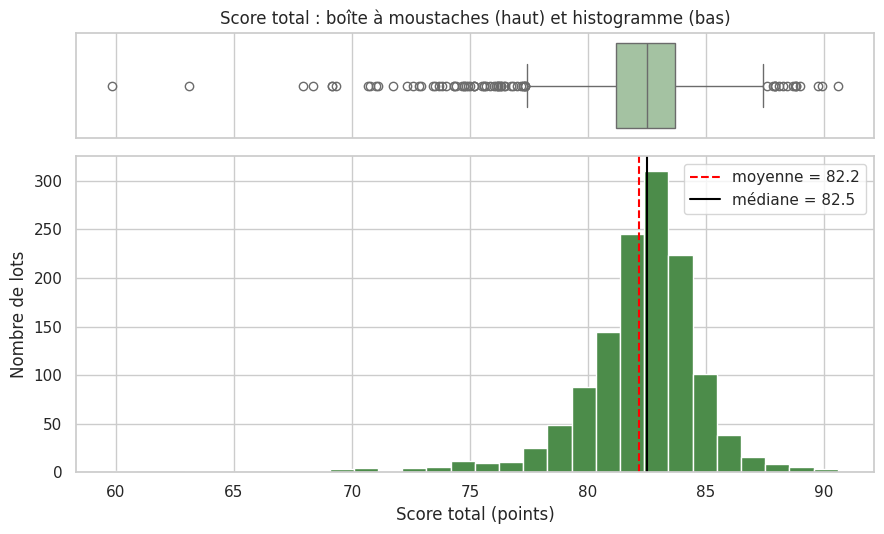

In [ ]:
s = df["score_total"]
print(f"moyenne = {s.mean():.2f} | médiane = {s.median():.2f} | écart-type = {s.std():.2f} | asymétrie (skew) = {s.skew():.2f}")
print(s.describe().round(2).to_string())

fig, (ax_box, ax_hist) = plt.subplots(2, 1, figsize=(9, 5.5), sharex=True,
                                      gridspec_kw={"height_ratios": [1, 3]})
sns.boxplot(x=s, ax=ax_box, color="#9fc79d")
ax_box.set_xlabel("")
ax_box.set_title("Score total : boîte à moustaches (haut) et histogramme (bas)")

ax_hist.hist(s, bins=30, color="#4c8c4a", edgecolor="white")
ax_hist.axvline(s.mean(), color="red", linestyle="--", label=f"moyenne = {s.mean():.1f}")
ax_hist.axvline(s.median(), color="black", linestyle="-", label=f"médiane = {s.median():.1f}")
ax_hist.set_xlabel("Score total (points)")
ax_hist.set_ylabel("Nombre de lots")
ax_hist.legend()
plt.tight_layout()
plt.show()

**Interprétation.**
- **Moyenne = 82,18 < médiane = 82,50** et asymétrie de **−1,84** : la distribution est étirée vers la gauche (quelques lots à faible score tirent la moyenne vers le bas).
- Le **cœur des données** (50 % centraux) est resserré entre **81,17 et 83,67**, soit seulement 2,5 points d'écart ; l'écart-type est 2,69.
- La boîte à moustaches **signale** de nombreux points isolés à gauche (et quelques-uns à droite), que l'histogramme montre à peine car leurs barres sont minuscules.
- Chiffre issu de la classification C.6 : **78,2 % des lots** sont « Spécialité » et **8,1 %** « Excellent ».

**Conclusion (Q1).** Le score total est concentré autour de 82–83 avec une queue de mauvais lots ; atteindre 85+ est rare (8 %).
**Limites.** Ni l'un ni l'autre ne dit **qui** sont les lots hors normes (pays ? méthode ?). Pour cela il faudra croiser avec d'autres variables.

## D.4 Camembert versus barres : lots par pays
**Question.** Quels pays sont les plus représentés dans les données ?
**Choix.** Test volontaire d'un **camembert** (37 catégories) face à des **barres horizontales triées**.

Nombre de pays : 37
pays
Mexico                    236
Colombia                  183
Guatemala                 181
Brazil                    132
Taiwan                     75
United States (Hawaii)     73
Honduras                   52
Costa Rica                 51


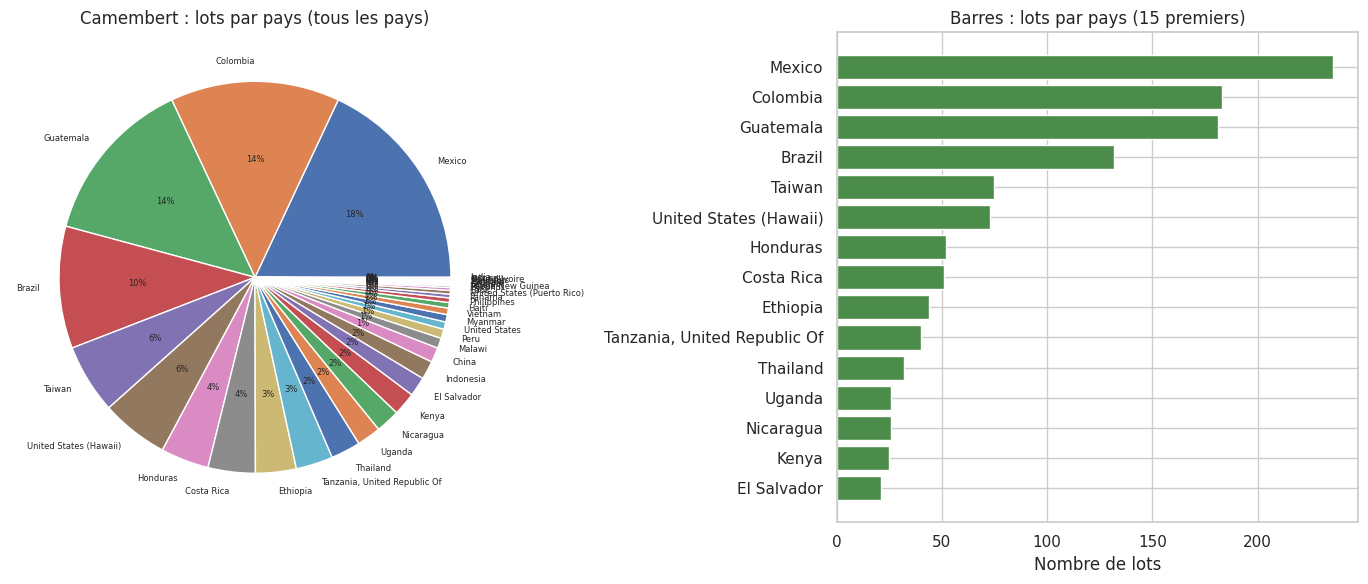

In [ ]:
effectifs_pays = df["pays"].value_counts()
print("Nombre de pays :", len(effectifs_pays))
print(effectifs_pays.head(8).to_string())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Camembert avec TOUS les pays
axes[0].pie(effectifs_pays.values, labels=effectifs_pays.index, autopct="%1.0f%%", textprops={"fontsize": 6})
axes[0].set_title("Camembert : lots par pays (tous les pays)")

# Barres horizontales triées (15 premiers pays)
top15 = effectifs_pays.head(15)
axes[1].barh(top15.index[::-1], top15.values[::-1], color="#4c8c4a")
axes[1].set_xlabel("Nombre de lots")
axes[1].set_title("Barres : lots par pays (15 premiers)")
plt.tight_layout()
plt.show()

**Interprétation.** Le camembert à gauche est **illisible** : plus de 30 petites parts, des étiquettes qui se chevauchent, et il est impossible de comparer Colombie (183) et Guatemala (181), pourtant presque identiques. Les barres de droite donnent immédiatement le **classement** : Mexique (236), Colombie (183), Guatemala (181), Brésil (132), puis Taïwan (75) et Hawaï (73).
**Conclusion.** Dès qu'il y a **beaucoup de catégories** ou qu'on veut **comparer** des valeurs proches, les barres sont bien supérieures : l'œil compare des longueurs alignées plus facilement que des angles.
**Limites.** Les barres ne montrent que les effectifs, pas la qualité. Plus important : les données **ne sont pas un échantillon représentatif de la production mondiale** (le Mexique en a 236 lots, certains pays n'en ont qu'1 ou 2) ; nous ne pourrons comparer que les pays avec assez de lots.

## D.5 Camembert versus barres : méthodes de traitement
**Question.** Quelle est la répartition des méthodes de traitement ?
**Choix.** Ici, avec **peu de catégories** et un but de « part d'un tout », le camembert est raisonnable : on compare les deux représentations.

traitement
Washed / Wet                 812
Natural / Dry                251
Inconnu                      151
Semi-washed / Semi-pulped     56
Other                         26
Pulped natural / honey        14
traitement
Washed / Wet                 62.0
Natural / Dry                19.2
Inconnu                      11.5
Semi-washed / Semi-pulped     4.3
Other                         2.0
Pulped natural / honey        1.1


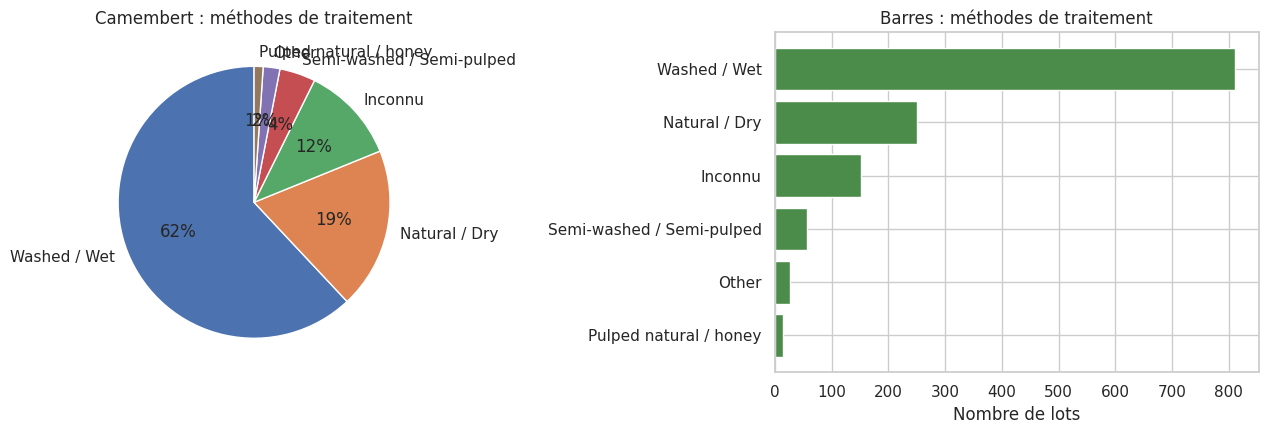

In [ ]:
effectifs_trait = df["traitement"].value_counts()
print(effectifs_trait.to_string())
print((effectifs_trait / len(df) * 100).round(1).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].pie(effectifs_trait.values, labels=effectifs_trait.index, autopct="%1.0f%%", startangle=90)
axes[0].set_title("Camembert : méthodes de traitement")

axes[1].barh(effectifs_trait.index[::-1], effectifs_trait.values[::-1], color="#4c8c4a")
axes[1].set_xlabel("Nombre de lots")
axes[1].set_title("Barres : méthodes de traitement")
plt.tight_layout()
plt.show()

**Interprétation.** La méthode **Washed / Wet** domine (812 lots, **62,0 %**), suivie de **Natural / Dry** (251 lots, 19,2 %). On note que **11,5 % des lots ont un traitement inconnu**, ce qui reste significatif. Le camembert montre bien la **dominance** de la méthode lavée ; en revanche, les trois plus petites parts (*Semi-washed* 4,3 %, *Other* 2,0 %, *Pulped natural* 1,1 %) sont collées en haut et **leurs étiquettes se chevauchent** : on ne peut pas les lire ni les comparer. Les barres, elles, les séparent clairement.
**Conclusion.** Pour **« quelle part du tout ? »** avec 5-6 catégories, camembert et barres conviennent ; pour **comparer précisément** les petites catégories, les barres sont meilleures.
**Limites.** Un effectif ne dit rien sur la qualité ; la comparaison des scores par méthode est faite en E.5.

## D.6 Les 10 critères de dégustation (Q2)
**Question.** Tous les critères de notation varient-ils autant ? Certains sont-ils quasi constants ?
**Choix.** Des boîtes à moustaches **côte à côte** sur la même échelle, pour comparer dispersions et niveaux entre critères. (Un histogramme par critère aurait demandé 10 graphiques.)

              mean   std   min    50%    max
arome         7.57  0.32  5.08   7.58   8.75
saveur        7.52  0.34  6.08   7.58   8.83
arriere_gout  7.40  0.35  6.17   7.42   8.67
acidite       7.54  0.32  5.25   7.50   8.75
corps         7.52  0.29  5.25   7.50   8.58
equilibre     7.52  0.35  6.08   7.50   8.75
uniformite    9.84  0.49  6.00  10.00  10.00
tasse_propre  9.84  0.72  0.00  10.00  10.00
douceur       9.91  0.45  1.33  10.00  10.00
impression    7.50  0.43  5.17   7.50  10.00


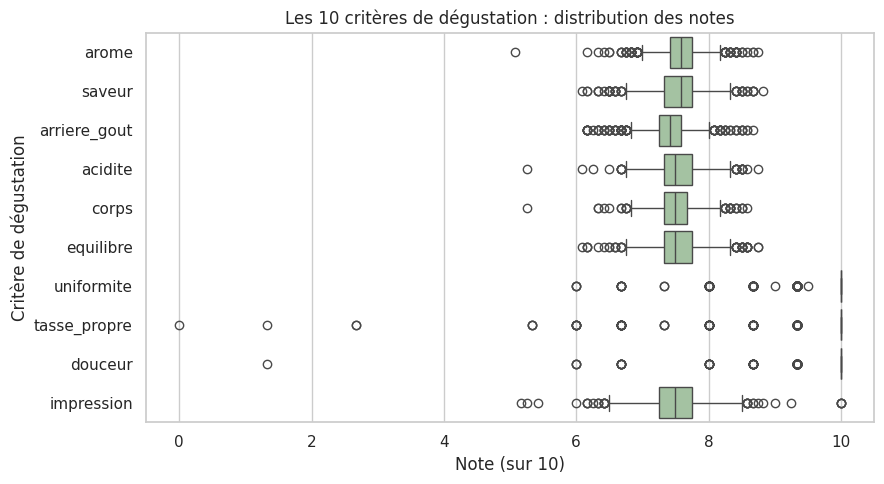

In [ ]:
print(df[notes_fr].describe().loc[["mean", "std", "min", "50%", "max"]].round(2).T)

plt.figure(figsize=(9, 5))
sns.boxplot(data=df[notes_fr], orient="h", color="#9fc79d")
plt.xlabel("Note (sur 10)")
plt.ylabel("Critère de dégustation")
plt.title("Les 10 critères de dégustation : distribution des notes")
plt.tight_layout()
plt.show()

**Interprétation.** On distingue **deux familles** de critères :
- Sept critères (`arome`, `saveur`, `arriere_gout`, `acidite`, `corps`, `equilibre`, `impression`) ont des médianes entre 7,4 et 7,6 et un écart-type de **0,29 à 0,43** : ils **discriminent** les lots.
- Trois critères (`uniformite`, `tasse_propre`, `douceur`) ont une médiane de **10** : presque tous les lots ont la note maximale (moyennes de 9,84 ; 9,84 ; 9,91), et seuls quelques lots s'écartent (points isolés à gauche).

**Conclusion (Q2, première partie).** Les trois critères « de régularité » **ne départagent presque aucun lot** ; ce sont des critères d'élimination plus que de classement. Ce sont les 7 critères sensoriels qui expliquent les différences de score.
**Limites.** Une médiane à 10 ne veut pas dire que ces critères sont inutiles : ils sanctionnent les rares lots défaillants (le minimum de `tasse_propre` est 0).

## D.7 Altitude et défauts
**Question.** Quelle est la forme de ces trois variables ?

Altitude : asymétrie = -0.59
Défauts cat. 1 : part de lots à 0 défaut = 84.7 %
Défauts cat. 2 : part de lots à 0 défaut = 27.6 %
       defauts_cat1  defauts_cat2
count       1310.00       1310.00
mean           0.43          3.59
std            1.83          5.35
min            0.00          0.00
25%            0.00          0.00
50%            0.00          2.00
75%            0.00          4.00
max           31.00         55.00


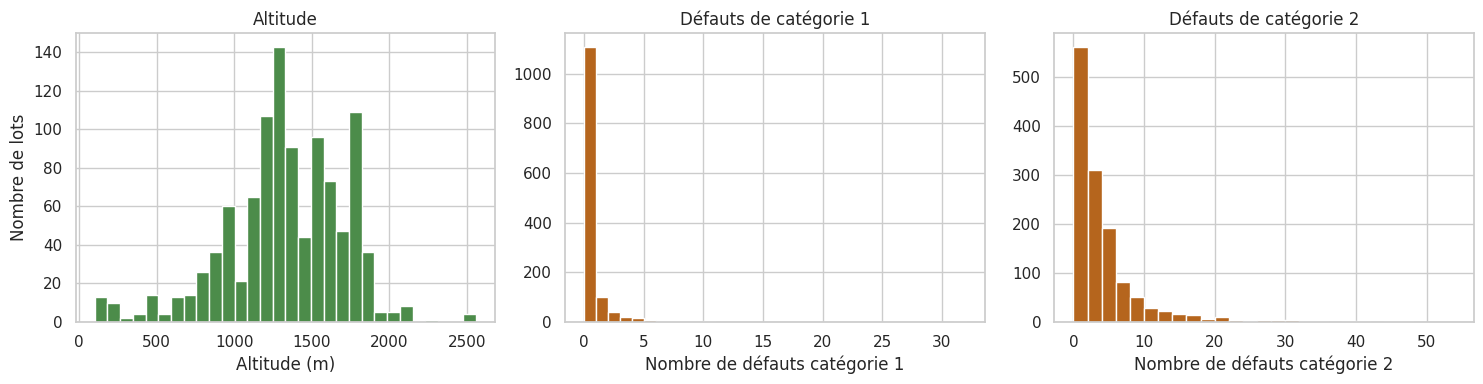

In [ ]:
print("Altitude : asymétrie =", round(df["altitude_m"].skew(), 2))
print("Défauts cat. 1 : part de lots à 0 défaut =", round((df["defauts_cat1"] == 0).mean() * 100, 1), "%")
print("Défauts cat. 2 : part de lots à 0 défaut =", round((df["defauts_cat2"] == 0).mean() * 100, 1), "%")
print(df[["defauts_cat1", "defauts_cat2"]].describe().round(2).to_string())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df["altitude_m"].dropna(), bins=30, color="#4c8c4a", edgecolor="white")
axes[0].set_xlabel("Altitude (m)"); axes[0].set_ylabel("Nombre de lots"); axes[0].set_title("Altitude")

axes[1].hist(df["defauts_cat1"], bins=range(0, 33), color="#b5651d", edgecolor="white")
axes[1].set_xlabel("Nombre de défauts catégorie 1"); axes[1].set_title("Défauts de catégorie 1")

axes[2].hist(df["defauts_cat2"], bins=range(0, 56, 2), color="#b5651d", edgecolor="white")
axes[2].set_xlabel("Nombre de défauts catégorie 2"); axes[2].set_title("Défauts de catégorie 2")
plt.tight_layout()
plt.show()

**Interprétation.**
- **Altitude** (lots à altitude connue) : distribution étalée entre 100 et 2560 m, légèrement asymétrique à gauche (asymétrie −0,59), avec une médiane d'environ 1318 m et **78,7 %** des lots entre 1000 et 1800 m.
- **Défauts de catégorie 1** : **84,7 % des lots n'en ont aucun**, mais le maximum est 31 : distribution très concentrée à 0 avec une longue queue.
- **Défauts de catégorie 2** : seulement 27,6 % des lots sont à 0 ; la médiane est 2 et le maximum 55.

**Conclusion.** Les défauts sont très **asymétriques** (beaucoup de petites valeurs, quelques cas extrêmes) : la moyenne y est peu représentative, il vaut mieux regarder la médiane ou des classes (d'où la variable `classe_defauts`).
**Limites.** Ces histogrammes ne disent pas si les lots très défectueux sont aussi ceux de moindre qualité : voir E.7.

---
# E. Analyse bivariée et multivariée

## E.1 Quels critères sont liés au score total ? (Q2)
**Question.** Quelles variables sont les plus corrélées au score total ? Les critères sont-ils redondants entre eux ?
**Choix.** Une **carte thermique** de la matrice de corrélation (TP2, Q22-Q23) : c'est la seule façon de voir ~14 variables d'un coup d'œil. Échelle de couleurs **centrée sur 0** (de −1 à 1) pour distinguer corrélations positives et négatives.

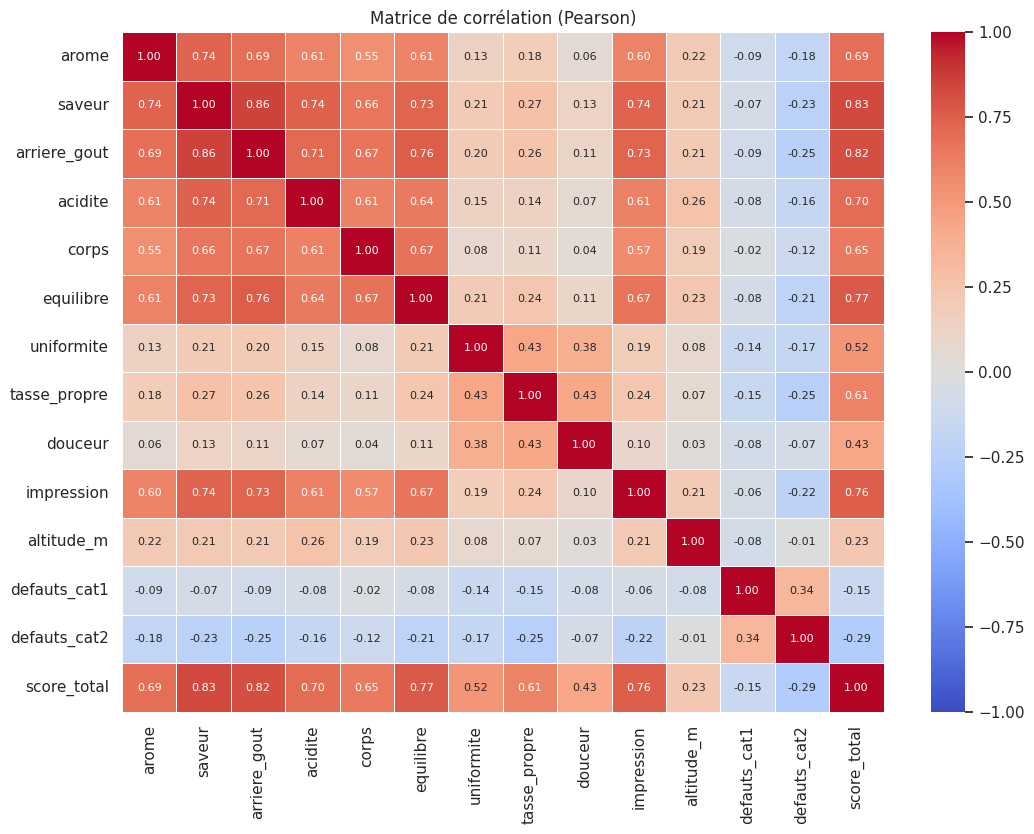

Corrélation de chaque variable avec score_total :
saveur          0.83
arriere_gout    0.82
equilibre       0.77
impression      0.76
acidite         0.70
arome           0.69
corps           0.65
tasse_propre    0.61
uniformite      0.52
douceur         0.43
altitude_m      0.23
defauts_cat1   -0.15
defauts_cat2   -0.29


In [ ]:
colonnes_corr = notes_fr + ["altitude_m", "defauts_cat1", "defauts_cat2", "score_total"]
corr = df[colonnes_corr].corr()

plt.figure(figsize=(11, 8.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, center=0,
            annot_kws={"size": 8}, linewidths=0.5)
plt.title("Matrice de corrélation (Pearson)")
plt.tight_layout()
plt.show()

print("Corrélation de chaque variable avec score_total :")
print(corr["score_total"].drop("score_total").sort_values(ascending=False).round(2).to_string())

**Interprétation.**
- Les plus fortes corrélations avec le score total : **`saveur` (0,83)**, **`arriere_gout` (0,82)**, `equilibre` (0,77), `impression` (0,76), `acidite` (0,70).
- Les plus faibles parmi les notes : `douceur` (0,43), `uniformite` (0,52).
- **Défauts** : corrélations **négatives** (cat. 2 : −0,29 ; cat. 1 : −0,15) ; **altitude** : faiblement positive (+0,23).

⚠️ **Attention, piège de lecture :** le score total **est la somme** des 10 notes ; sa corrélation avec chacune est donc en partie **mécanique** (une note qui varie beaucoup influence mécaniquement le total). Il ne faut pas en conclure que `saveur` « cause » un bon score. L'information plus intéressante est la corrélation **entre critères**, calculée ci-dessous.

In [ ]:
# Corrélations entre critères seulement (sans score_total, qui en est la somme)
c2 = df[notes_fr].corr()
paires = c2.where(np.triu(np.ones(c2.shape), k=1).astype(bool)).stack().dropna().sort_values()
print("Paires les moins corrélées :\n", paires.head(4).round(2).to_string())
print("\nPaires les plus corrélées :\n", paires.tail(4).round(2).to_string())

Paires les moins corrélées :
 corps    douceur       0.04
arome    douceur       0.06
acidite  douceur       0.07
corps    uniformite    0.08

Paires les plus corrélées :
 saveur        impression      0.74
              acidite         0.74
arriere_gout  equilibre       0.76
saveur        arriere_gout    0.86


**Interprétation.** `saveur` et `arriere_gout` sont fortement liés (**0,86**) : un lot qui a une bonne saveur a presque toujours un bon arrière-goût. À l'inverse, `douceur` est **quasi indépendante** des autres critères (0,04 à 0,07 avec `corps`, `arome`, `acidite`) : c'est cohérent avec la note quasi constante à 10 vue en D.6.
**Conclusion (Q2).** Les critères sensoriels sont **redondants** entre eux (ils mesurent en partie la même « qualité globale »), alors que `douceur` apporte peu d'information distincte.
**Limites de la heatmap.** Elle ne détecte que les relations **linéaires**, ne montre pas la forme du nuage ni les valeurs isolées, et résume tout en un seul nombre. C'est ce que montre le comparatif suivant.

## E.2 Nuage de points versus matrice de nuages (pairplot)
**Question.** La corrélation de 0,86 entre `saveur` et `arriere_gout` a-t-elle une forme particulière ? Voit-on des cas à part ?
**Choix.** D'abord un **nuage simple** (TP2, Q16) puis un **pairplot** coloré par classe de qualité (TP2, Q19) pour voir 4 variables et un regroupement à la fois.

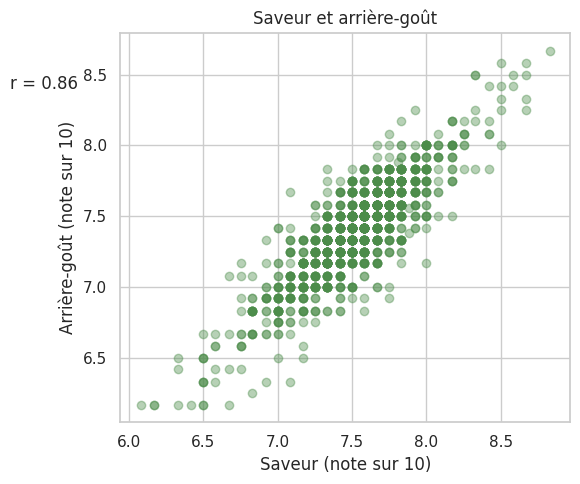

In [ ]:
plt.figure(figsize=(6, 5))
plt.scatter(df["saveur"], df["arriere_gout"], alpha=0.4, color="#4c8c4a")
plt.xlabel("Saveur (note sur 10)")
plt.ylabel("Arrière-goût (note sur 10)")
plt.title("Saveur et arrière-goût")
r = df["saveur"].corr(df["arriere_gout"])
plt.text(5.2, 8.4, f"r = {r:.2f}")
plt.tight_layout()
plt.show()

**Interprétation du nuage simple.** On voit bien une relation **positive et linéaire** avec r = 0,86. Mais **on ne sait pas** si certains lots forment un groupe particulier.

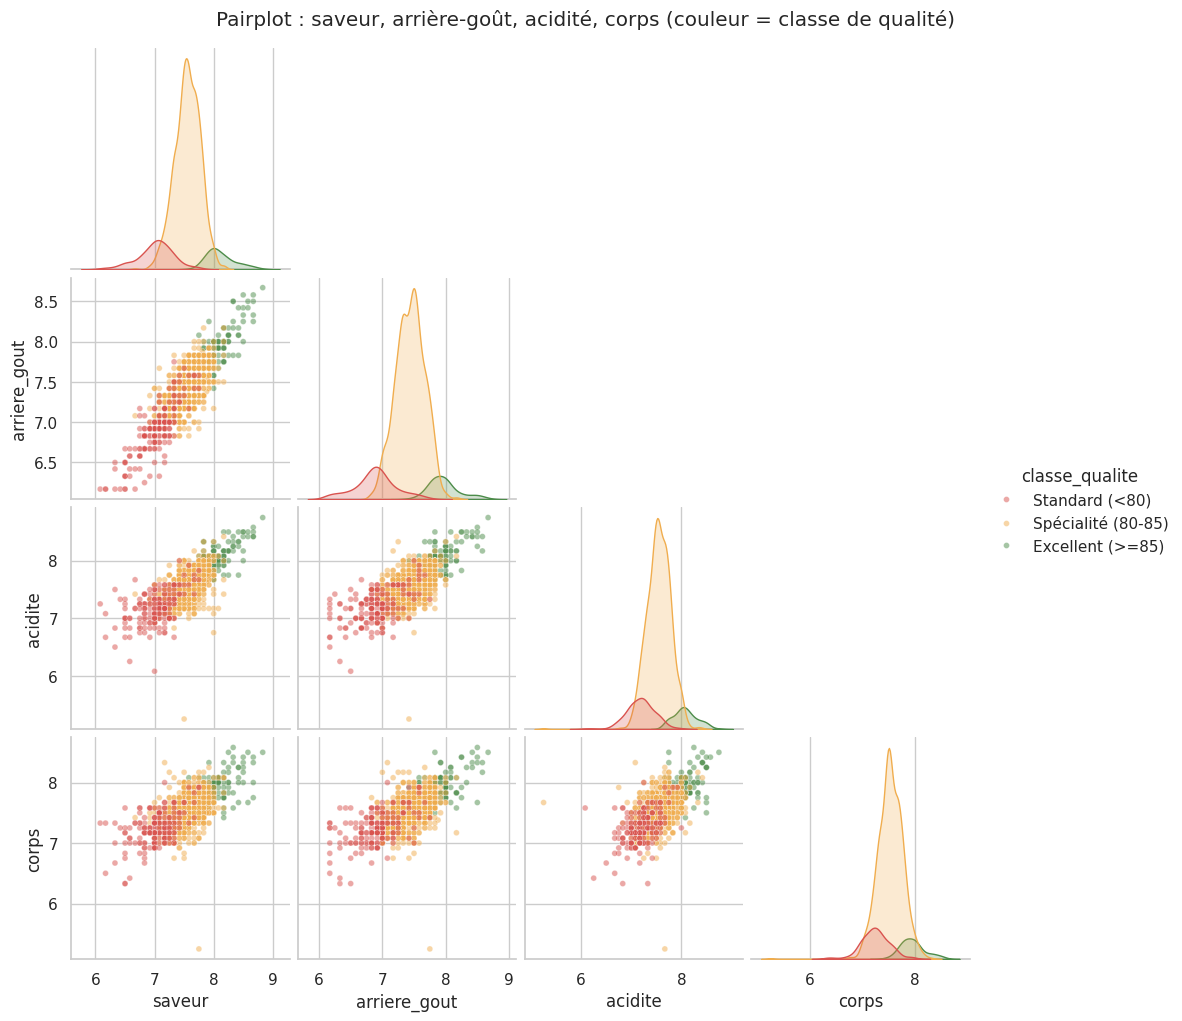

In [ ]:
# Pairplot : 4 variables, coloré par classe de qualité (comme Q19 du TP2)
sns.pairplot(df[["saveur", "arriere_gout", "acidite", "corps", "classe_qualite"]],
             hue="classe_qualite", plot_kws={"alpha": 0.5, "s": 18}, corner=True,
             palette={"Standard (<80)": "#d9534f", "Spécialité (80-85)": "#f0ad4e", "Excellent (>=85)": "#4c8c4a"})
plt.suptitle("Pairplot : saveur, arrière-goût, acidité, corps (couleur = classe de qualité)", y=1.02)
plt.show()

**Interprétation du pairplot.** Il apporte ce que ni la heatmap ni le nuage simple ne montraient :
- Les points suivent une **grille** (les notes sont données par pas d'environ 0,08) : ce sont des **valeurs discrètes**, pas continues.
- Les trois classes de qualité sont bien **ordonnées** dans l'espace saveur/arrière-goût : les lots « Excellent » (vert) sont en haut à droite, les « Standard » (rouge) en bas à gauche.
- Un point isolé (un lot avec `corps` ≈ 5,25 mais classé « Spécialité ») sort du nuage ; la heatmap ne pouvait pas le montrer.

**Conclusion.** La heatmap donne la **vue d'ensemble** (quelles variables sont liées), le pairplot en donne la **forme** (linéarité, grille, points isolés, groupes). Les deux répondent à des questions différentes.
**Limites.** Les classes de qualité sont **définies à partir du total**, donc leur bonne séparation sur les notes est en partie **attendue**, pas une découverte. Le pairplot est aussi limité à 3-5 variables : au-delà il devient illisible.

## E.3 Les pays se distinguent-ils ? (Q3)
**Question.** Quel pays a les meilleurs scores ? Les écarts sont-ils nets, et les pays sont-ils homogènes en interne ?
**Choix.** On ne compare que les pays avec **au moins 20 lots** (sinon une moyenne n'est pas fiable). On teste deux graphiques : **barres de moyennes** versus **boîtes à moustaches**.

In [ ]:
# Pays comparés : seulement ceux avec au moins 20 lots (sinon la moyenne n'est pas fiable)
n_par_pays = df["pays"].value_counts()
pays_ok = n_par_pays[n_par_pays >= 20].index
dfp = df[df["pays"].isin(pays_ok)]

resume_pays = dfp.groupby("pays")["score_total"].agg(["count", "mean", "median", "std"]).round(2)
resume_pays["part_specialite_%"] = (dfp.groupby("pays")["score_total"].apply(lambda s: (s >= 80).mean()) * 100).round(0)
resume_pays = resume_pays.sort_values("median", ascending=False)
print("Pays retenus :", len(pays_ok), "| lots couverts :", len(dfp), "sur", len(df))
resume_pays

Pays retenus : 16 | lots couverts : 1217 sur 1310


,count,mean,median,std,part_specialite_%
pays,,,,,
Ethiopia,44,85.48,85.20,2.34,100.0
Kenya,25,84.31,84.58,1.46,96.0
Uganda,26,84.05,83.88,1.36,100.0
Colombia,183,83.11,83.25,1.41,97.0
Costa Rica,51,82.79,83.25,2.38,92.0
El Salvador,21,83.05,82.83,1.60,95.0
United States (Hawaii),73,81.82,82.75,2.99,78.0
Thailand,32,82.57,82.67,1.55,91.0
Indonesia,20,82.57,82.66,2.42,90.0


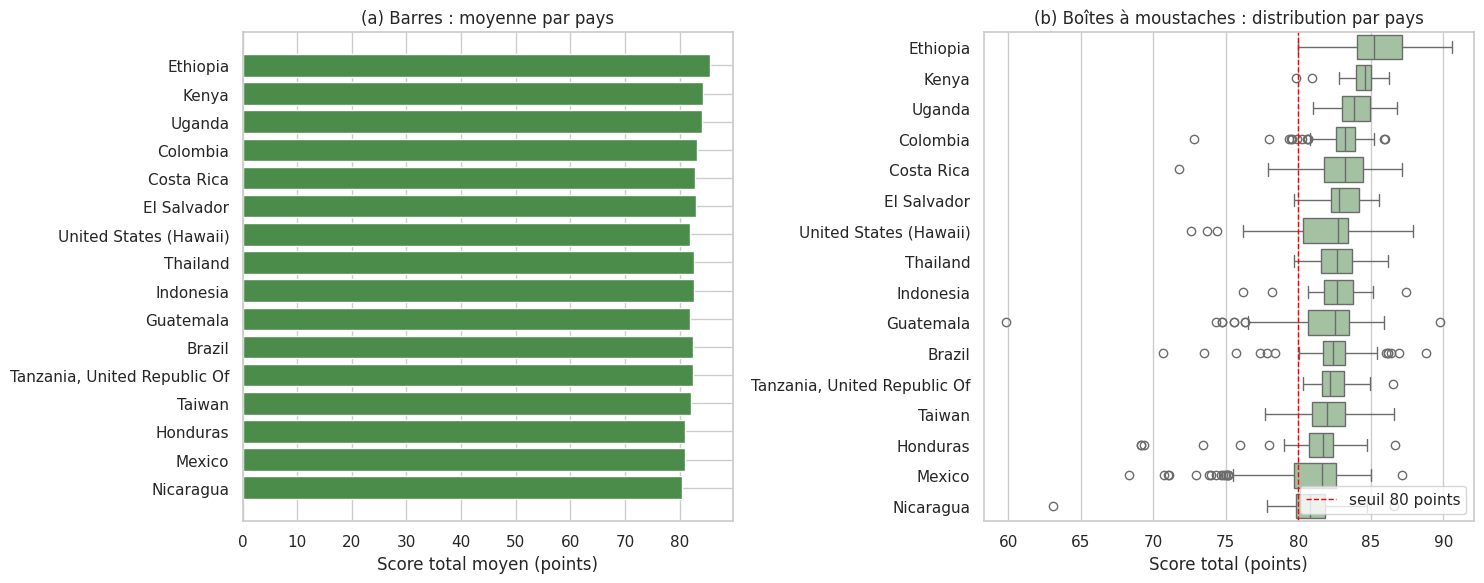

In [ ]:
ordre = resume_pays.sort_values("median", ascending=False).index

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# (a) barres de la moyenne : une seule valeur par pays
moy = resume_pays.loc[ordre, "mean"]
axes[0].barh(ordre[::-1], moy.values[::-1], color="#4c8c4a")
axes[0].set_xlabel("Score total moyen (points)")
axes[0].set_title("(a) Barres : moyenne par pays")

# (b) boîtes à moustaches : toute la distribution
sns.boxplot(data=dfp, y="pays", x="score_total", order=ordre, ax=axes[1], color="#9fc79d")
axes[1].axvline(80, color="red", linestyle="--", linewidth=1, label="seuil 80 points")
axes[1].legend(loc="lower right")
axes[1].set_xlabel("Score total (points)")
axes[1].set_ylabel("")
axes[1].set_title("(b) Boîtes à moustaches : distribution par pays")
plt.tight_layout()
plt.show()

**Interprétation.**
- **Graphique (a), barres de la moyenne :** les 16 barres sont **presque de même longueur** (de 80,5 à 85,5 sur une échelle qui commence à 0) : on conclurait « tous les pays se valent ». Les barres cachent aussi la dispersion.
- **Graphique (b), boîtes à moustaches :** on voit immédiatement ce que la moyenne cache :
  - **Éthiopie** : médiane 85,2, tous ses lots sont ≥ 80 (100 % « spécialité ») mais avec une **grande dispersion vers le haut** (certains lots proches de 90).
  - **Colombie** : médiane 83,25 et boîte **très étroite** (écart-type 1,41) : un pays **homogène**, 97 % de lots ≥ 80.
  - **Mexique** (médiane 81,6, 69 % de lots ≥ 80), **Honduras** et **Nicaragua** (écarts-types de 3,56 et 4,08, et 73 % à 85 % ≥ 80) : des pays **moins réguliers**, avec de nombreux lots bas.
  - Les pays à forte médiane ne sont pas ceux qui ont le plus de lots : Éthiopie 44, Kenya 25, Ouganda 26.

**Conclusion (Q3).** Oui, les pays diffèrent, mais **la différence est une affaire de distribution** (niveau, régularité, lots très bas) bien plus que de moyenne.
**Limites.** Un pays avec 25 lots (Kenya) ne se compare pas avec un pays à 236 lots ; ces lots sont **ceux qui ont été soumis à l'évaluation** (pas forcément représentatifs de tout le café du pays). Rien ne dit que le pays *cause* la qualité : il regroupe climat, variétés, pratiques, etc.

## E.4 Altitude et score : une relation qui cache autre chose ? (Q4)
**Question.** Les cafés cultivés plus haut ont-ils un meilleur score ? Et cette relation survit-elle quand on compare des lots **du même pays** ?
**Choix.** Quatre représentations successives, du plus pauvre au plus riche :
(a) nuage avec les altitudes brutes ; (b) nuage nettoyé ; (c) nuage coloré par pays avec une droite par pays ; (d) boîtes par classe d'altitude. Puis un chiffre de contrôle : la corrélation **à l'intérieur de chaque pays**.

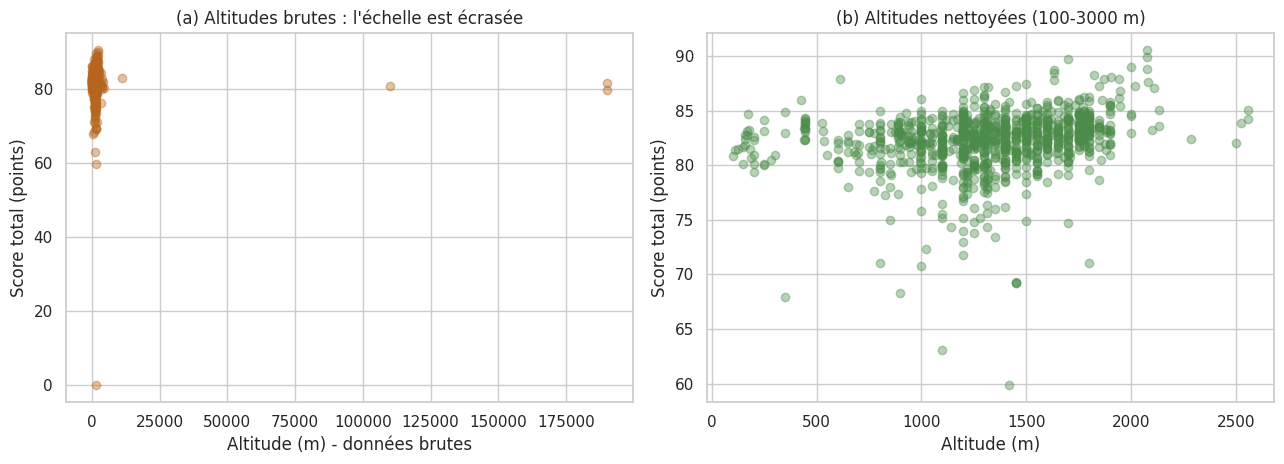

Lots avec altitude exploitable : 1051
Corrélation globale altitude / score : 0.23


In [ ]:
# (a) Avec les altitudes BRUTES (non nettoyées)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

axes[0].scatter(brut["altitude_mean_meters"], brut["Total.Cup.Points"], alpha=0.4, color="#b5651d")
axes[0].set_xlabel("Altitude (m) - données brutes")
axes[0].set_ylabel("Score total (points)")
axes[0].set_title("(a) Altitudes brutes : l'échelle est écrasée")

# (b) Altitudes nettoyées
axes[1].scatter(df["altitude_m"], df["score_total"], alpha=0.4, color="#4c8c4a")
axes[1].set_xlabel("Altitude (m)")
axes[1].set_ylabel("Score total (points)")
axes[1].set_title("(b) Altitudes nettoyées (100-3000 m)")
plt.tight_layout()
plt.show()

sous = df[["altitude_m", "score_total"]].dropna()
print("Lots avec altitude exploitable :", len(sous))
print("Corrélation globale altitude / score :", round(sous["altitude_m"].corr(sous["score_total"]), 2))

**Interprétation (a vs b).** À gauche, avec les altitudes brutes, tous les points sont **tassés contre l'axe vertical** : à cause de la valeur à 190 164 m, l'échelle va jusqu'à 200 000 m et on ne voit aucune relation. À droite, après nettoyage, le nuage devient lisible et on devine une tendance légèrement croissante. La corrélation globale est de **+0,23** sur 1051 lots.
**Leçon.** Un mauvais nettoyage peut **faire disparaître** une relation du graphique (ici, sans nettoyage, la conclusion serait « pas de lien »).

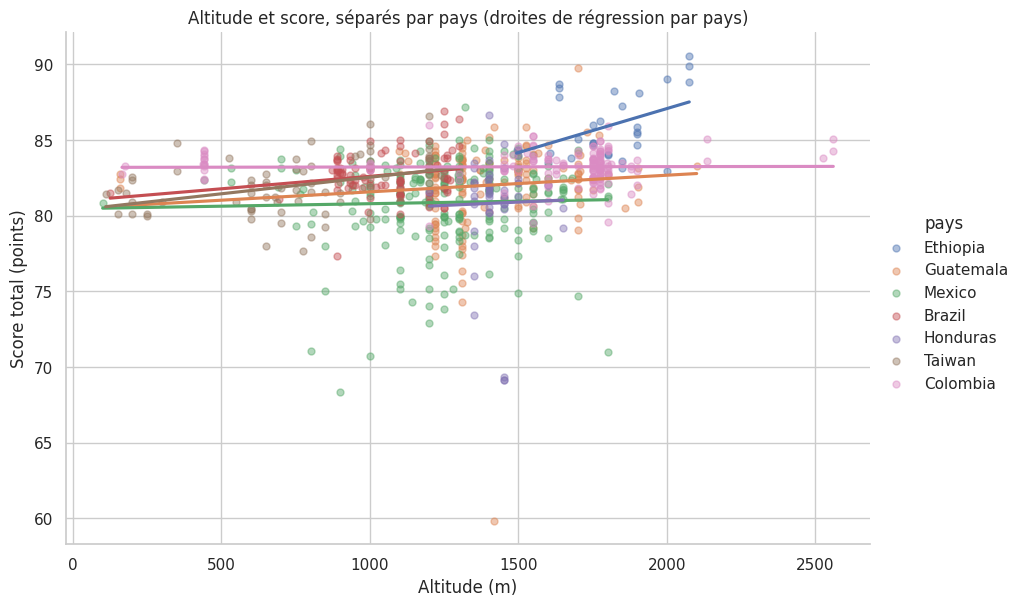

In [ ]:
# Un nuage par pays : les 6 pays les plus représentés (altitude connue) + l'Éthiopie
top6 = list(df.dropna(subset=["altitude_m"])["pays"].value_counts().head(6).index) + ["Ethiopia"]
d6 = df[df["pays"].isin(top6)].dropna(subset=["altitude_m"])

sns.lmplot(data=d6, x="altitude_m", y="score_total", hue="pays", height=6, aspect=1.5,
           ci=None, scatter_kws={"alpha": 0.45, "s": 25})
plt.xlabel("Altitude (m)")
plt.ylabel("Score total (points)")
plt.title("Altitude et score, séparés par pays (droites de régression par pays)")
plt.show()

**Interprétation (c).** Quand on colore par pays, on constate :
- Les nuages se **superposent partiellement mais se placent à des niveaux différents** : Colombie en haut (score ≈ 83), Mexique et Honduras plus bas.
- Les **droites par pays sont presque plates** pour la Colombie, le Mexique et le Honduras, modérément inclinées pour Taïwan, le Brésil et le Guatemala, et **nettement plus pentues pour l'Éthiopie** (en bleu), dont les 30 lots sont tous à plus de 1500 m avec des scores élevés.
Autrement dit, une partie de la tendance globale vient du fait que **les pays de haute altitude (Colombie, Éthiopie) ont aussi de bons scores**, et pas uniquement de l'altitude elle-même.

In [ ]:
# Corrélation altitude / score À L'INTÉRIEUR de chaque pays (au moins 30 lots avec altitude)
lignes = []
for p, g in df.dropna(subset=["altitude_m"]).groupby("pays"):
    if len(g) >= 30:
        lignes.append((p, len(g), round(g["altitude_m"].median()), round(g["altitude_m"].corr(g["score_total"]), 2)))
interne = pd.DataFrame(lignes, columns=["pays", "n_lots", "altitude_mediane_m", "corr_altitude_score"])
interne = interne.sort_values("corr_altitude_score", ascending=False)
print(interne.to_string(index=False))
print("\nMoyenne simple des corrélations internes :", round(interne["corr_altitude_score"].mean(), 2),
      "| corrélation globale :", round(sous["altitude_m"].corr(sous["score_total"]), 2))

                        pays  n_lots  altitude_mediane_m  corr_altitude_score
                    Ethiopia      30                1800                 0.42
                      Taiwan      69                 750                 0.39
                  Costa Rica      44                1300                 0.24
                      Brazil      91                1050                 0.20
                   Guatemala     151                1384                 0.10
                      Mexico     231                1250                 0.03
                    Honduras      50                1400                 0.02
                    Colombia     149                1750                 0.01
Tanzania, United Republic Of      37                1600                -0.08

Moyenne simple des corrélations internes : 0.15 | corrélation globale : 0.23


**Interprétation (chiffres).** La corrélation **à l'intérieur de chaque pays** varie fortement :
- **positive et marquée** : Éthiopie (0,42), Taïwan (0,39), Costa Rica (0,24), Brésil (0,20) ;
- **nulle ou très faible** : Mexique (0,03), Honduras (0,02), Colombie (0,01), Guatemala (0,10) ;
- **légèrement négative** : Tanzanie (−0,08).
La moyenne de ces corrélations internes (0,15) est **plus faible** que la corrélation globale (0,23).

                 count   mean  median
classe_altitude                      
<1000 m            196  81.77   82.21
1000-1500 m        517  81.71   82.25
1500-2000 m        324  83.13   83.17
>2000 m             14  85.77   85.08


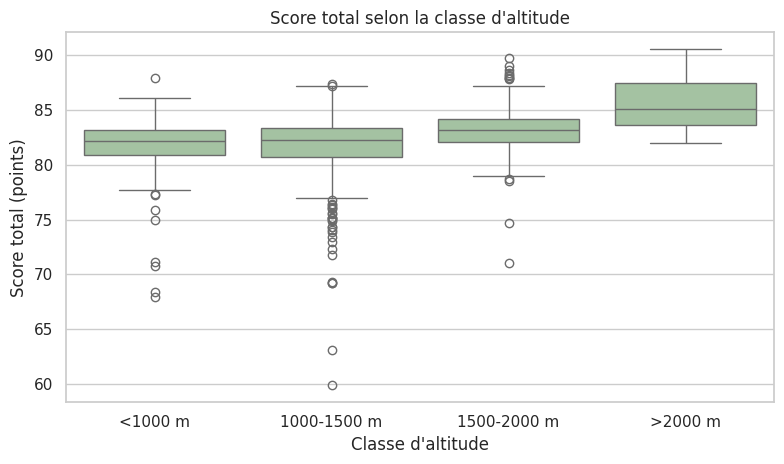

In [ ]:
# Même question avec la variable discrétisée en classes d'altitude (pd.cut, comme au TP3 III)
res_alt = df.groupby("classe_altitude", observed=True)["score_total"].agg(["count", "mean", "median"]).round(2)
print(res_alt)

plt.figure(figsize=(8, 4.8))
sns.boxplot(data=df, x="classe_altitude", y="score_total", color="#9fc79d")
plt.xlabel("Classe d'altitude")
plt.ylabel("Score total (points)")
plt.title("Score total selon la classe d'altitude")
plt.tight_layout()
plt.show()

**Interprétation (d).** Les scores moyens restent presque identiques pour les lots **< 1000 m** (81,77) et **1000–1500 m** (81,71), puis **augmentent** à 1500–2000 m (83,13) et au-delà de 2000 m (85,77). La relation n'est donc **pas linéaire** : l'effet apparaît surtout à partir de 1500 m.

**Conclusion (Q4).** Il existe une **association positive mais modeste** entre altitude et score. Une partie provient d'un **effet de composition** (certains pays cumulent haute altitude et bons scores), et **à l'intérieur de plusieurs grands pays producteurs la relation est quasi nulle**. On ne peut donc pas affirmer que « plus haut = meilleur café » de façon générale.
**Limites.**
- Seuls **14 lots** dépassent 2000 m : le chiffre de 85,77 est fragile.
- Corrélation ≠ causalité : l'altitude peut être liée à la variété, au climat, au savoir-faire.
- 20 % des altitudes sont manquantes ou ont été invalidées ; nous avons vérifié que leur absence ne change pas le score moyen (C.5), mais pas qu'elles sont réparties de la même façon dans tous les pays.
- La corrélation de Pearson ne mesure que les liens linéaires, ce qui explique pourquoi (d) montre mieux la forme réelle.

## E.5 Lavé ou naturel : un « meilleur » traitement ? (Q5)
**Question.** La méthode de traitement a-t-elle un effet sur le score ? Le même résultat vaut-il dans tous les pays ?
**Choix.** D'abord la **moyenne globale**, puis la comparaison **par pays**. Pour la partie par pays, un graphique en **points** (et non des barres) car les différences sont petites : des barres tronquées exagéreraient les écarts, des barres commençant à 0 les rendraient invisibles.

In [ ]:
# Les deux méthodes principales seulement (les autres ont trop peu de lots)
dt = df[df["traitement"].isin(["Washed / Wet", "Natural / Dry"])]
print("Moyenne globale par méthode :")
print(dt.groupby("traitement")["score_total"].agg(["count", "mean", "median"]).round(2))

# Pays ayant au moins 8 lots dans CHAQUE méthode
effectifs = dt.groupby(["pays", "traitement"]).size().unstack(fill_value=0)
pays_both = effectifs[(effectifs["Washed / Wet"] >= 8) & (effectifs["Natural / Dry"] >= 8)].index
print("\nPays comparables :", list(pays_both))
tab = (dt[dt["pays"].isin(pays_both)].groupby(["pays", "traitement"])["score_total"].mean()
         .unstack().round(2))
tab["ecart (Natural - Washed)"] = (tab["Natural / Dry"] - tab["Washed / Wet"]).round(2)
tab

Moyenne globale par méthode :
               count   mean  median
traitement                         
Natural / Dry    251  82.35   82.75
Washed / Wet     812  81.96   82.42

Pays comparables : ['Colombia', 'Ethiopia', 'Guatemala', 'Honduras', 'Mexico', 'Taiwan', 'United States (Hawaii)']


traitement,Natural / Dry,Washed / Wet,ecart (Natural - Washed)
pays,,,
Colombia,83.06,83.33,-0.27
Ethiopia,85.41,86.47,-1.06
Guatemala,83.12,81.64,1.48
Honduras,81.14,80.53,0.61
Mexico,82.05,80.70,1.35
Taiwan,82.33,81.67,0.66
United States (Hawaii),81.07,81.92,-0.85


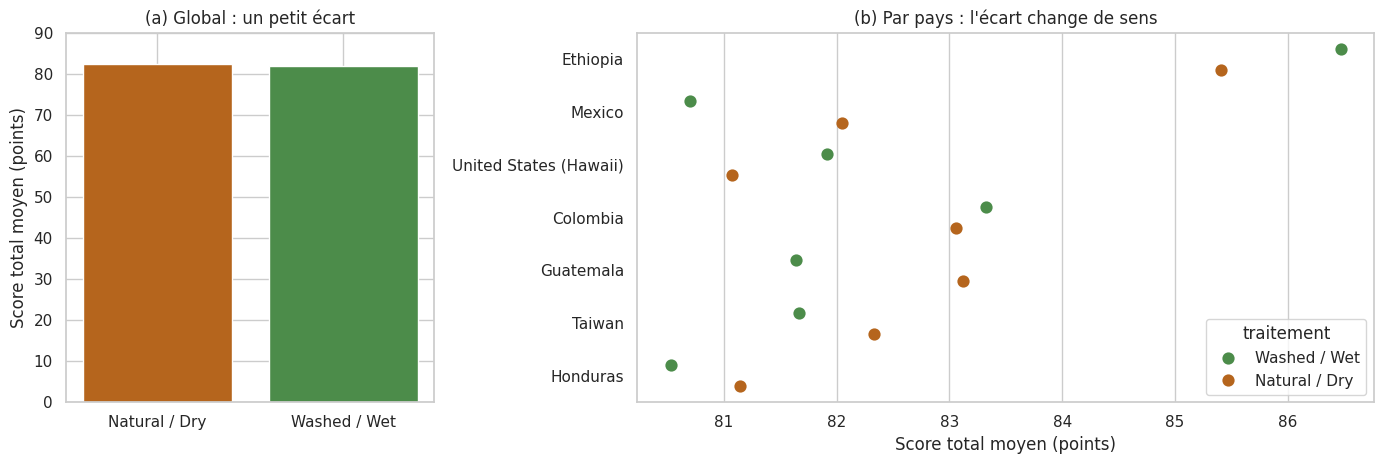

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8), gridspec_kw={"width_ratios": [1, 2]})

# (a) comparaison globale
glob = dt.groupby("traitement")["score_total"].mean()
axes[0].bar(glob.index, glob.values, color=["#b5651d", "#4c8c4a"])
axes[0].set_ylim(0, 90)
axes[0].set_ylabel("Score total moyen (points)")
axes[0].set_title("(a) Global : un petit écart")

# (b) par pays : points (pas de barres, pour ne pas tronquer l'axe)
sns.pointplot(data=dt[dt["pays"].isin(pays_both)], x="score_total", y="pays", hue="traitement",
              linestyle="none", dodge=0.4, errorbar=None, ax=axes[1],
              palette={"Washed / Wet": "#4c8c4a", "Natural / Dry": "#b5651d"})
axes[1].set_xlabel("Score total moyen (points)")
axes[1].set_ylabel("")
axes[1].set_title("(b) Par pays : l'écart change de sens")
plt.tight_layout()
plt.show()

In [ ]:
# D'où viennent les lots de chaque méthode ? (part de chaque pays, en %)
compo = (dt.groupby("traitement")["pays"].value_counts(normalize=True).mul(100).round(1).unstack(0))
compo.sort_values("Natural / Dry", ascending=False).head(5)

traitement,Natural / Dry,Washed / Wet
pays,,
Brazil,31.9,0.7
United States (Hawaii),15.9,1.1
Colombia,10.8,14.9
Ethiopia,6.8,1.0
Mexico,6.8,24.4


**Interprétation.**
- **Global (a)** : les lots *Natural / Dry* ont une moyenne de **82,35** contre **81,96** pour *Washed / Wet*, soit **+0,39 point** : un écart minuscule, que le graphique en barres rend presque invisible (les deux barres paraissent identiques).
- **Par pays (b)** : le sens de l'écart **change** : *Natural* fait mieux au Guatemala (+1,48), au Mexique (+1,35), à Taïwan (+0,66) et au Honduras (+0,61), mais fait **moins bien** en Éthiopie (−1,06), à Hawaï (−0,85) et en Colombie (−0,27).

**Conclusion (Q5).** **Il n'y a pas de « meilleure méthode » universelle** dans ces données : l'écart global est faible et change de signe selon le pays. Le tableau de composition ci-dessus montre pourquoi : les lots *Natural* viennent surtout du **Brésil** et de **Hawaï**, tandis que les lots *Washed* viennent surtout du **Mexique** (l'un des pays aux scores les plus faibles de notre comparaison, voir E.3) et de la Colombie. L'écart global mélange donc l'effet de la méthode et l'effet du pays (**effet de composition**).
**Limites.** Peu de lots par couple pays/méthode (au moins 8) : les moyennes sont fragiles. On ne contrôle ni la variété ni l'altitude ; une étude plus poussée nécessiterait des tests statistiques (hors programme de nos TP).

## E.6 Évolution dans le temps (Q6)
**Question.** Le score moyen évolue-t-il d'une année à l'autre ?
**Choix.** Un graphique en barres du **nombre de lots par année** à côté d'une **courbe du score moyen** annotée avec les effectifs : une courbe seule laisserait croire que toutes les années ont le même poids.

        count   mean
annee               
2010.0     50  84.14
2011.0     83  82.77
2012.0    314  81.36
2013.0    152  82.22
2014.0    246  81.80
2015.0    195  82.69
2016.0    123  83.04
2017.0    139  82.09
2018.0      6  82.94


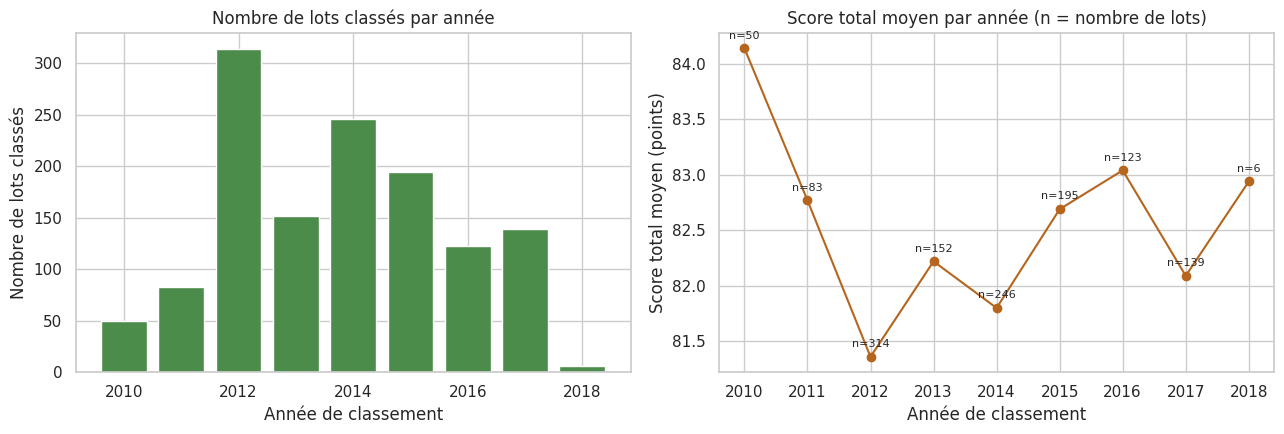

In [ ]:
par_annee = df.groupby("annee")["score_total"].agg(["count", "mean"]).round(2)
print(par_annee)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(par_annee.index.astype(int), par_annee["count"], color="#4c8c4a")
axes[0].set_xlabel("Année de classement")
axes[0].set_ylabel("Nombre de lots classés")
axes[0].set_title("Nombre de lots classés par année")

axes[1].plot(par_annee.index.astype(int), par_annee["mean"], marker="o", color="#b5651d")
for a, row in par_annee.iterrows():
    axes[1].annotate(f"n={int(row['count'])}", (a, row["mean"]), textcoords="offset points", xytext=(0, 7),
                     ha="center", fontsize=8)
axes[1].set_xlabel("Année de classement")
axes[1].set_ylabel("Score total moyen (points)")
axes[1].set_title("Score total moyen par année (n = nombre de lots)")
plt.tight_layout()
plt.show()

**Interprétation.** Le nombre de lots varie beaucoup : **314 lots en 2012**, 246 en 2014, mais seulement **50 en 2010** et **6 en 2018**. Le score moyen ne suit **pas de tendance claire** : 84,14 en 2010, 81,36 en 2012, 83,04 en 2016. Les années extrêmes reposent sur très peu de lots (2010 : n=50 ; 2018 : n=6).
**Conclusion (Q6, partie 1).** Les données **ne montrent pas d'amélioration ni de dégradation régulière** de la qualité dans le temps. Les écarts d'une année à l'autre peuvent venir de la **composition** (quels pays ont soumis leurs lots cette année-là) plutôt que d'un changement de qualité réel ; nous n'avons pas testé cette hypothèse.
**Limites.** L'année de classement est la date d'évaluation, pas la date de récolte ; la période (2010-2018) est courte.

## E.7 Les défauts font-ils baisser le score ? (Q6)
**Question.** Un lot avec davantage de défauts de catégorie 2 a-t-il un score plus bas ?
**Choix.** (a) un nuage de points ; (b) des boîtes par **classe de défauts**. Le nuage souffre de **superposition** (beaucoup de lots ont le même nombre de défauts), la discrétisation par `pd.cut` rend la comparaison lisible.

                count   mean  median
classe_defauts                      
0 défaut          362  82.58   82.67
1-5 défauts       701  82.42   82.75
6+ défauts        247  80.90   81.75
Corrélation défauts cat.2 / score : -0.29


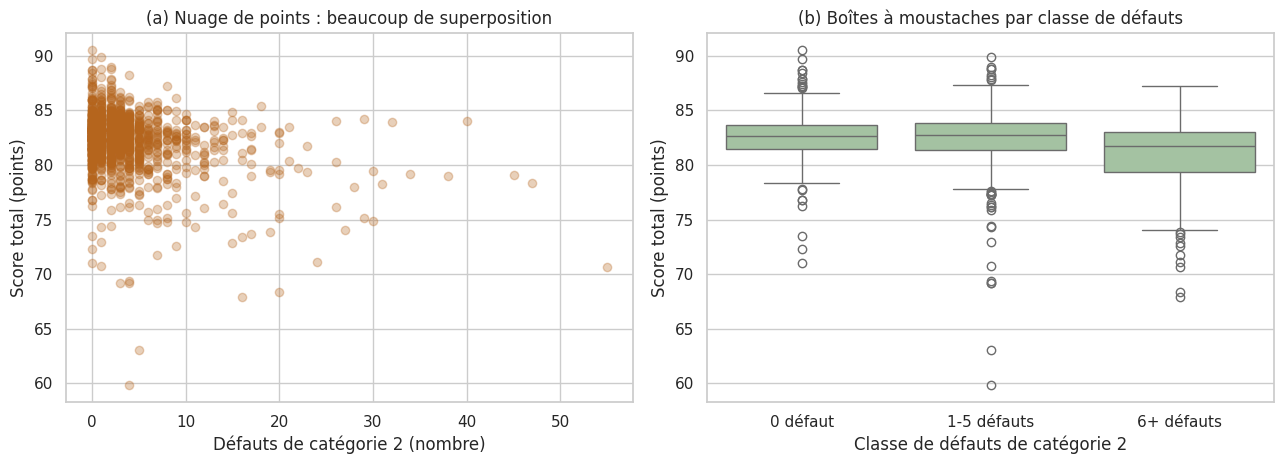

In [ ]:
print(df.groupby("classe_defauts", observed=True)["score_total"].agg(["count", "mean", "median"]).round(2))
print("Corrélation défauts cat.2 / score :", round(df["defauts_cat2"].corr(df["score_total"]), 2))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].scatter(df["defauts_cat2"], df["score_total"], alpha=0.3, color="#b5651d")
axes[0].set_xlabel("Défauts de catégorie 2 (nombre)")
axes[0].set_ylabel("Score total (points)")
axes[0].set_title("(a) Nuage de points : beaucoup de superposition")

sns.boxplot(data=df, x="classe_defauts", y="score_total", color="#9fc79d", ax=axes[1])
axes[1].set_xlabel("Classe de défauts de catégorie 2")
axes[1].set_ylabel("Score total (points)")
axes[1].set_title("(b) Boîtes à moustaches par classe de défauts")
plt.tight_layout()
plt.show()

**Interprétation.**
- Dans le nuage (a), la corrélation est de **−0,29**, mais **à l'œil nu on ne voit pas de tendance nette** : les points sont **superposés en colonnes** (beaucoup de lots ont 0 à 5 défauts), et on ne voit pas où se trouve la majorité des lots.
- Les boîtes (b) précisent : les lots avec **0 défaut** (82,58) et **1 à 5 défauts** (82,42) ont des scores **presque identiques**, alors que les lots avec **6 défauts ou plus** descendent à **80,90**.

**Conclusion (Q6, partie 2).** Les défauts sont associés à un score plus bas **seulement au-delà d'un certain seuil** (environ 6 défauts de catégorie 2) : quelques défauts sont **sans effet visible**. La relation n'est pas une droite.
**Limites.** Association, pas causalité ; les défauts sont aussi corrélés aux notes sensorielles (un lot défectueux a plus de chances d'être mal noté). Le seuil de 6 est un choix de discrétisation, pas une valeur « naturelle ».

## E.8 Les lots atypiques sont-ils des erreurs ? (Q7)
**Question.** Les 73 lots signalés par l'IQR (≈ 5,6 %) sont-ils des erreurs de saisie ou des cas réels ? D'où viennent-ils ?
**Choix.** Un **tableau** croisant les valeurs hors bornes (basses / hautes) avec le pays : plus précis qu'un graphique pour dénombrer.

In [ ]:
# Lots atypiques : méthode IQR sur le score total nettoyé
bas, haut = bornes_iqr(df["score_total"])
atypiques = df[(df["score_total"] < bas) | (df["score_total"] > haut)]
print(f"Bornes IQR : [{bas:.2f} ; {haut:.2f}] -> {len(atypiques)} lots atypiques "
      f"({len(atypiques) / len(df) * 100:.1f} % des lots)")
print("Atypiques bas :", (atypiques["score_total"] < bas).sum(), "| atypiques hauts :", (atypiques["score_total"] > haut).sum())

# z-score
z = (df["score_total"] - df["score_total"].mean()) / df["score_total"].std()
print("Lots avec |z| > 3 :", (z.abs() > 3).sum())

# Où sont-ils ? (part des lots atypiques par pays, pays >= 20 lots)
t = dfp.assign(bas=dfp["score_total"] < bas, haut=dfp["score_total"] > haut)
part = t.groupby("pays")[["bas", "haut"]].sum().astype(int)
part["total"] = part["bas"] + part["haut"]
part["part_%"] = (part["total"] / t.groupby("pays").size() * 100).round(1)
print(part.sort_values("total", ascending=False).head(6))

print("\nLes 5 scores les plus bas :")
atypiques.sort_values("score_total").head(5)[["pays", "traitement", "score_total", "defauts_cat2", "classe_qualite"]]

Bornes IQR : [77.42 ; 87.42] -> 73 lots atypiques (5.6 % des lots)
Atypiques bas : 57 | atypiques hauts : 16
Lots avec |z| > 3 : 22
                        bas  haut  total  part_%
pays                                            
Mexico                   22     0     22     9.3
Guatemala                10     1     11     6.1
Ethiopia                  0     9      9    20.5
United States (Hawaii)    6     1      7     9.6
Brazil                    4     1      5     3.8
Honduras                  5     0      5     9.6

Les 5 scores les plus bas :


,pays,traitement,score_total,defauts_cat2,classe_qualite
1309,Guatemala,Washed / Wet,59.83,4,Standard (<80)
1308,Nicaragua,Other,63.08,5,Standard (<80)
1307,Haiti,Natural / Dry,67.92,16,Standard (<80)
1306,Mexico,Washed / Wet,68.33,20,Standard (<80)
1304,Honduras,Washed / Wet,69.17,3,Standard (<80)


**Interprétation.** Sur 73 lots atypiques, **57 sont trop bas et 16 trop hauts**. Ils sont très concentrés :
- **Mexique** : 22 lots atypiques, **tous bas** (9,3 % de ses lots) ;
- **Guatemala** : 11 (dont 10 bas) ;
- **Éthiopie** : 9 lots atypiques, **tous hauts** (20,5 % de ses lots) : ce sont les meilleurs cafés du jeu de données, pas des erreurs.

Les scores les plus bas (59,8 ; 63,1 ; 67,9…) sont cohérents (le total reste égal à la somme des notes, voir B.5) : ce ne sont pas des erreurs de saisie, contrairement au lot à 0.
**Conclusion (Q7).** « Aberrant » ne veut pas dire « faux » (esprit critique du TP3 E.4) : ces lots sont **des informations**, ils ne doivent pas être supprimés. Les lots atypiques bas caractérisent surtout le Mexique ; les atypiques hauts, l'Éthiopie.
**Limites.** La règle IQR s'appuie sur **toutes les données mélangées** ; un lot « normal » pour l'Éthiopie serait un lot atypique pour un autre pays.

---
# F. Bilan : pourquoi certains graphiques montrent mieux que d'autres

| Question | Graphique « faible » | Ce qu'il masque ou fausse | Graphique « fort » | Ce qu'il révèle |
|---|---|---|---|---|
| Forme du score (D.1) | Histogramme **avant** nettoyage | Un lot à 0 écrase l'échelle | Histogramme **après** nettoyage | Distribution en cloche, queue à gauche |
| Nombre de classes (D.2) | Histogramme à 5 classes | Forme masquée (1 bloc de 1000+ lots) | Histogramme à 20-60 classes | Forme lisible |
| Résumé de distribution (D.3) | Histogramme seul | Valeurs atypiques à peine visibles | Histogramme + boîte alignés | Médiane, quartiles, asymétrie, atypiques |
| Pays (D.4) | **Camembert** de 37 parts | Illisible, parts proches indiscernables | Barres triées | Classement net |
| Pays vs score (E.3) | Barres de moyennes | Tous les pays semblent égaux, dispersion cachée | Boîtes à moustaches triées | Niveaux, régularité, lots bas |
| Corrélations (E.1-E.2) | Heatmap seule | Forme, grille, points isolés | Heatmap + pairplot | Vue d'ensemble **et** forme des relations |
| Altitude (E.4) | Nuage brut | Valeur à 190 164 m écrase tout | Nuage nettoyé, **coloré par pays** | Tendance globale vs tendances par pays |
| Traitement (E.5) | Barres globales | Écart minuscule, signe qui change selon le pays | Points par pays | Absence de « meilleure » méthode |
| Défauts (E.7) | Nuage de points | Superposition en colonnes | Boîtes par classe de défauts | Effet seulement au-delà d'un seuil |

> **Ce qu'on retient :** un graphique n'est pas « joli » ou « moche » en soi ; il est **adapté ou non** à la question. Un camembert ou une barre de moyenne peuvent être propres visuellement tout en cachant l'information essentielle.

---
# Conclusion générale

**Réponse à la problématique.** Dans ces données, la qualité d'un lot de café arabica n'est pas expliquée par un facteur unique :

1. **Le score est concentré** (médiane 82,5 ; 50 % des lots entre 81,2 et 83,7) avec une queue de mauvais lots ; 78,2 % des lots sont « Spécialité » et seulement 8,1 % « Excellent » (Q1).
2. **Sept critères sensoriels** structurent le score et sont fortement liés entre eux ; trois critères (`uniformite`, `tasse_propre`, `douceur`) sont presque toujours à 10 et départagent peu (Q2).
3. **Le pays compte**, surtout par la **régularité** de ses lots : l'Éthiopie a les meilleurs lots, la Colombie est la plus régulière, le Mexique, le Honduras et le Nicaragua ont plus de lots faibles (Q3).
4. **L'altitude est modestement associée au score** (r = 0,23), mais cette association est en partie un effet des pays et disparaît presque dans plusieurs grands pays producteurs (Q4).
5. **Aucune méthode de traitement n'est « meilleure »** : l'écart global de 0,39 point change de signe selon le pays (Q5).
6. **Pas de tendance temporelle claire** ; **les défauts ne pénalisent le score qu'au-delà d'environ 6 défauts de catégorie 2** (Q6).
7. **Les lots atypiques sont réels** (Mexique : lots bas ; Éthiopie : lots excellents) et doivent être conservés (Q7).

**Ce que les traitements et les graphiques ont apporté.** Sans nettoyage, l'altitude moyenne aurait été de 1784 m (au lieu de 1327 m) et la relation altitude/score aurait paru inexistante. Sans comparer plusieurs graphiques, on aurait conclu que « tous les pays se valent » (barres de moyenne) et qu'« il n'y a pas de différence de traitement ». Ces deux conclusions, **visibles seulement après** un bon choix de visualisation, ne se lisaient pas en regardant les premières lignes du fichier.

### Limites de l'étude
- Les lots sont **ceux qui ont été soumis à évaluation** : pas un échantillon aléatoire de la production mondiale.
- Plusieurs pays ont peu de lots ; la tranche > 2000 m n'en contient que 14.
- Nous n'avons utilisé que des **corrélations et des comparaisons de moyennes/médianes**, sans test statistique : on décrit, on ne prouve pas.
- La classe « Spécialité » repose sur un seuil conventionnel (80 points).
- Les relations pays / altitude / traitement sont **entremêlées** ; nous ne les avons séparées que partiellement.

### Améliorations possibles
- Analyser la **variété** (`variete`) et la région, après regroupement des petites catégories.
- Utiliser des **tests statistiques** (comparaison de groupes) pour vérifier si les différences sont significatives.
- Étudier l'effet du pays **à altitude comparable** avec une régression (méthode plus avancée que nos TP).
- Utiliser `Harvest.Year` après un nettoyage plus poussé du texte.

## Export du jeu de données nettoyé

In [ ]:
# Sauvegarde du jeu de données nettoyé (sans l'index, comme au TP3 V.4)
df.to_csv("cafe_arabica_propre.csv", index=False)
print("Fichier exporté :", df.shape)

Fichier exporté : (1310, 30)
